# NeuroSense Speech Intelligence — Google Colab GPU Migration & Pipeline

This notebook provides an end-to-end workflow for running the **NeuroSense Speech Intelligence** project on Google Colab with GPU acceleration.

### Pipeline Phases Covered:
- **Phase A & B**: Environment setup, GPU diagnostics, and audio preprocessing configuration.
- **Phase C**: Participant-level stratified splits & zero participant overlap validation.
- **Phase D**: End-to-end 3-stream inference integration test (`Wav2Vec2`, `Whisper`, `DistilRoBERTa`, `SpeechFusion`).
- **Phase E**: Supervised training of projection layers, fusion MLP & dementia classifier head with early stopping and persistent Google Drive checkpointing.

## 1. Mount Google Drive

In [ ]:
# 1. Mount Google Drive for persistent storage of project ZIP, dataset, and checkpoints
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Environment & GPU Hardware Diagnostics

In [ ]:
import torch
import sys
import psutil

print("=" * 65)
print("--- NeuroSense Environment & Hardware Diagnostics ---")
print(f"Python Version : {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"GPU Memory     : {vram_gb:.2f} GB")
else:
    print("WARNING: CUDA is not available. Execution will fall back to CPU.")
ram_gb = psutil.virtual_memory().total / (1024**3)
ram_avail = psutil.virtual_memory().available / (1024**3)
print(f"System RAM     : {ram_gb:.2f} GB total ({ram_avail:.2f} GB available)")
print("=" * 65)

!nvidia-smi

--- NeuroSense Environment & Hardware Diagnostics ---
Python Version : 3.13.15
PyTorch Version: 2.11.0+cu128
CUDA Available : True
GPU Device Name: Tesla T4
GPU Memory     : 14.56 GB
System RAM     : 12.67 GB total (11.17 GB available)
Sat Sep 26 16:20:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    

## 3. Install Compatible Python Dependencies

In [ ]:
# Install required packages
!pip install -q torch torchaudio transformers datasets scipy numpy pyyaml psutil tqdm scikit-learn pandas

## 4. Extract Project Code Archive & Configure Package Import Path

In [ ]:

from pathlib import Path
import zipfile
import sys

# Correct Google Drive location
PROJECT_ZIP = Path(
    "/content/drive/MyDrive/NeuroSense/NeuroSense_Colab_Project.zip"
)

# Colab extraction directory
PROJECT_ROOT = Path("/content/NeuroSense")

assert PROJECT_ZIP.is_file(), (
    f"Project ZIP not found: {PROJECT_ZIP}\n"
    "Check that Google Drive is mounted."
)

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(PROJECT_ZIP, "r") as z:
    bad_file = z.testzip()
    assert bad_file is None, f"Corrupt ZIP member: {bad_file}"
    z.extractall(PROJECT_ROOT)

print("Project extracted successfully.")
print("Top-level files:")
for p in PROJECT_ROOT.iterdir():
    print(" -", p.name)

# Find the actual location of the speech_model package
packages = list(PROJECT_ROOT.rglob("speech_model/__init__.py"))

assert packages, (
    "speech_model/__init__.py not found in the extracted ZIP."
)

package_dir = packages[0].parent
project_parent = package_dir.parent

sys.path.insert(0, str(project_parent))

import speech_model

print("Successfully imported speech_model!")
print("Package location:", speech_model.__file__)

Project extracted successfully.
Top-level files:
 - speech_model
 - requirements.txt
 - NeuroSense_Colab.ipynb
Successfully imported speech_model!
Package location: /content/NeuroSense/speech_model/__init__.py


## 5. Extract Authorized Dataset & Update Manifest Paths

In [ ]:
import os
from pathlib import Path
from speech_model.data.resolve_paths import update_manifest_paths

# DATASET_ZIP = "/content/drive/MyDrive/NeuroSense_Audio_Data.zip"

DATASET_ZIP = "/content/drive/MyDrive/NeuroSense/NeuroSense_Audio_Data.zip"
DATA_EXTRACT_PATH = "/content/data"

if os.path.exists(DATASET_ZIP):
    print(f"Extracting dataset from {DATASET_ZIP} to {DATA_EXTRACT_PATH}...")
    !unzip -q -o "{DATASET_ZIP}" -d "{DATA_EXTRACT_PATH}"
else:
    print(f"[INFO] Dataset ZIP not found at {DATASET_ZIP}. Verify raw audio is present at {DATA_EXTRACT_PATH}.")

# Dynamically update manifests to resolve audio paths in Colab
manifest_dir = Path(target_root) / "speech_model" / "data" / "manifests"
for mf in ["train.csv", "valid.csv", "test.csv", "master.csv"]:
    mp = manifest_dir / mf
    if mp.exists():
        update_manifest_paths(mp, data_root=DATA_EXTRACT_PATH)

Extracting dataset from /content/drive/MyDrive/NeuroSense/NeuroSense_Audio_Data.zip to /content/data...


In [ ]:

from pathlib import Path

print("Current target_root:", target_root)

print("\nSearching for manifest files...")
for csv_file in Path("/content/NeuroSense").rglob("train.csv"):
    print("Found:", csv_file)
    print("Manifest directory:", csv_file.parent)
    print("Project root:", csv_file.parent.parent.parent.parent)

print("\nChecking expected project directory:")
print("Exists:", Path("/content/NeuroSense").exists())

Current target_root: /content

Searching for manifest files...
Found: /content/NeuroSense/speech_model/data/manifests/train.csv
Manifest directory: /content/NeuroSense/speech_model/data/manifests
Project root: /content/NeuroSense

Checking expected project directory:
Exists: True


In [ ]:
target_root = "/content/NeuroSense"

from pathlib import Path

manifest_dir = Path(target_root) / "speech_model" / "data" / "manifests"

for name in ["train.csv", "valid.csv", "test.csv", "master.csv"]:
    print(name, (manifest_dir / name).exists())

train.csv True
valid.csv True
test.csv True
master.csv True


In [ ]:
from speech_model.data.resolve_paths import update_manifest_paths

for name in ["train.csv", "valid.csv", "test.csv", "master.csv"]:
    path = manifest_dir / name

    if not path.is_file():
        raise FileNotFoundError(path)

    update_manifest_paths(
        path,
        data_root="/content/data"
    )

    print("Updated:", name)

Updated 277 paths in train.csv
Updated: train.csv
Updated 55 paths in valid.csv
Updated: valid.csv
Updated 69 paths in test.csv
Updated: test.csv
Updated 545 paths in master.csv
Updated: master.csv


## 6. Validate Manifests & Verify Zero Participant Overlap

In [ ]:
import csv
from pathlib import Path

manifest_dir = Path(target_root) / "speech_model" / "data" / "manifests"

def get_pids(csv_file):
    pids = set()
    with open(csv_file, newline='', encoding='utf-8') as f:
        for r in csv.DictReader(f):
            pids.add(r['participant_id'])
    return pids

train_pids = get_pids(manifest_dir / "train.csv")
valid_pids = get_pids(manifest_dir / "valid.csv")
test_pids  = get_pids(manifest_dir / "test.csv")

tv_overlap = train_pids & valid_pids
tt_overlap = train_pids & test_pids
vt_overlap = valid_pids & test_pids

print(f"Train Participants: {len(train_pids)}")
print(f"Valid Participants: {len(valid_pids)}")
print(f"Test  Participants: {len(test_pids)}")

if tv_overlap or tt_overlap or vt_overlap:
    raise ValueError(f"Participant overlap detected! TV={tv_overlap}, TT={tt_overlap}, VT={vt_overlap}")
else:
    print("SUCCESS: Zero participant overlap verified across all split sets!")

Train Participants: 171
Valid Participants: 37
Test  Participants: 37
SUCCESS: Zero participant overlap verified across all split sets!


In [ ]:

from pathlib import Path
import csv
import os

DATA_ROOT = Path("/content/data")
MANIFEST = Path(
    "/content/NeuroSense/speech_model/data/manifests/train.csv"
)

print("=== 1. DATASET DIRECTORY ===")
print("Data directory exists:", DATA_ROOT.exists())

if DATA_ROOT.exists():
    for p in DATA_ROOT.iterdir():
        print(" ", p.name, "[DIR]" if p.is_dir() else "[FILE]")

print("\n=== 2. ACTUAL AUDIO FILES ===")
wav_files = list(DATA_ROOT.rglob("*.wav"))
wav_files += list(DATA_ROOT.rglob("*.WAV"))

print("Total WAV files found:", len(wav_files))

for p in wav_files[:5]:
    print("Actual WAV:", p)

print("\n=== 3. CSV MANIFEST ===")
print("Manifest exists:", MANIFEST.exists())

if MANIFEST.exists():
    with MANIFEST.open(
        "r", encoding="utf-8-sig", newline=""
    ) as f:
        reader = csv.DictReader(f)
        print("CSV columns:", reader.fieldnames)
        rows = list(reader)

    print("Total CSV rows:", len(rows))

    for row in rows[:5]:
        print("\nCSV row:", row)

        for key, value in row.items():
            if key and (
                "path" in key.lower()
                or "file" in key.lower()
            ):
                print(
                    f"{key} exists:",
                    os.path.isfile(value or "")
                )

=== 1. DATASET DIRECTORY ===
Data directory exists: True
  raw [DIR]

=== 2. ACTUAL AUDIO FILES ===
Total WAV files found: 544
Actual WAV: /content/data/raw/controled/118-0 (1).wav
Actual WAV: /content/data/raw/controled/245-1 (1).wav
Actual WAV: /content/data/raw/controled/034-3.wav
Actual WAV: /content/data/raw/controled/121-1 (1).wav
Actual WAV: /content/data/raw/controled/118-3 (1).wav

=== 3. CSV MANIFEST ===
Manifest exists: True
CSV columns: ['audio_path', 'label', 'participant_id', 'session', 'is_copy', 'duration_s', 'sample_rate', 'channels', 'file_bytes', 'sha256', 'readable', 'error', 'source']
Total CSV rows: 277

CSV row: {'audio_path': 'c:\\Users\\Dharmaraj\\Downloads\\speech proceesing\\speech_model\\data\\raw\\dementia\\046-0.wav', 'label': 'dementia', 'participant_id': '046', 'session': '0', 'is_copy': 'False', 'duration_s': '61.013', 'sample_rate': '44100', 'channels': '1', 'file_bytes': '5381412', 'sha256': 'cd72d883cd4427645226d67f70b8b3fb8bb02ac1307fb3f4c8bb349b762

In [ ]:

from pathlib import Path
import csv
import shutil
from pathlib import PureWindowsPath

MANIFEST_DIR = Path(
    "/content/NeuroSense/speech_model/data/manifests"
)
DATA_ROOT = Path("/content/data")

for name in ["train.csv", "valid.csv", "test.csv", "master.csv"]:
    csv_path = MANIFEST_DIR / name

    if not csv_path.is_file():
        raise FileNotFoundError(csv_path)

    with csv_path.open(
        "r", encoding="utf-8-sig", newline=""
    ) as f:
        reader = csv.DictReader(f)
        fields = reader.fieldnames
        rows = list(reader)

    if "audio_path" not in fields:
        raise ValueError(f"{name}: audio_path column missing")

    updates = []
    missing = []

    for row in rows:
        old_path = row["audio_path"]

        # Extract the original raw/category/filename structure
        parts = PureWindowsPath(old_path).parts
        lower_parts = [p.lower() for p in parts]

        if "raw" not in lower_parts:
            missing.append(old_path)
            continue

        raw_index = lower_parts.index("raw")
        relative_path = Path(*parts[raw_index:])
        new_path = DATA_ROOT / relative_path

        if new_path.is_file():
            updates.append((row, str(new_path)))
        else:
            missing.append(str(new_path))

    print(f"\n{name}")
    print("Total records:", len(rows))
    print("Matched audio:", len(updates))
    print("Missing audio:", len(missing))

    if missing:
        print("First missing paths:")
        for p in missing[:5]:
            print(" ", p)
        print("Not modifying this manifest.")
        continue

    # Back up the manifest before changing it
    backup = csv_path.with_suffix(".windows_backup.csv")
    if not backup.exists():
        shutil.copy2(csv_path, backup)

    for row, new_path in updates:
        row["audio_path"] = new_path

    with csv_path.open(
        "w", encoding="utf-8", newline=""
    ) as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

    print("Manifest updated successfully.")


train.csv
Total records: 277
Matched audio: 277
Missing audio: 0
Manifest updated successfully.

valid.csv
Total records: 55
Matched audio: 55
Missing audio: 0
Manifest updated successfully.

test.csv
Total records: 69
Matched audio: 69
Missing audio: 0
Manifest updated successfully.

master.csv
Total records: 545
Matched audio: 545
Missing audio: 0
Manifest updated successfully.


In [ ]:

from pathlib import Path
import csv

for name in ["train.csv", "valid.csv", "test.csv", "master.csv"]:
    csv_path = MANIFEST_DIR / name

    with csv_path.open(
        "r", encoding="utf-8", newline=""
    ) as f:
        rows = list(csv.DictReader(f))

    accessible = sum(
        Path(row["audio_path"]).is_file()
        for row in rows
    )

    print(
        f"{name}: {accessible}/{len(rows)} accessible"
    )

train.csv: 277/277 accessible
valid.csv: 55/55 accessible
test.csv: 69/69 accessible
master.csv: 545/545 accessible


## 7. Phase D End-to-End Integration Test (GPU Acceleration)

In [ ]:
import torch
from speech_model.data.integration_test import run_integration_test

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Executing Phase D Integration Test on device: {device}...")
run_integration_test(data_root=DATA_EXTRACT_PATH, device=device)

Executing Phase D Integration Test on device: cuda...
PHASE D -- Integration Test

  Audio file : /content/data/raw/dementia/046-0.wav
  Format     : WAV  SR=44100 Hz  CH=1  dur=61.0s

  Running predict() on cuda ...
--- Hardware & Environment Info ---
CUDA Available: True
Device: cuda
System RAM: 12.67 GB total, 10.07 GB available
GPU Memory: 14.56 GB total (Tesla T4)
[1/5] Loading and preprocessing audio from /content/data/raw/dementia/046-0.wav...
      Original recording duration: 61.01 seconds
      Elapsed time: 1.32s
[2/5] Wav2Vec2 model initialization and inference...


preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.27GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

... (25 outputs left out)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

      Elapsed time: 13.83s
[5/5] Speech fusion...
      Elapsed time: 0.03s
Total inference time: 44.80s
Actual bottleneck: Wav2Vec2 (17.13s)

  Transcript : " There it is. Go. Go. Mother's washing dishes. The kids are looking for cookies. They're little girls crying because the"...
  Sentiment  : sadness  (prob_sum=1.0000)
  Probs      : {'anger': 0.168, 'disgust': 0.173, 'fear': 0.018, 'joy': 0.009, 'neutral': 0.21, 'sadness': 0.262, 'surprise': 0.161}
  acoustic_embedding: shape=(256,) finite=True  norm=1.6838
  affective_embedding: shape=(256,) finite=True  norm=6.8591
  speech_embedding: shape=(256,) finite=True  norm=1.2266

[PASS] Phase D integration test passed successfully.
  Sample result saved -> /content/NeuroSense/speech_model/data/manifests/integration_test_result.json


In [ ]:

from pathlib import Path
import sys
import os
import importlib.util

ROOT = Path("/content/NeuroSense")
PKG = ROOT / "speech_model"
TRAINING = PKG / "training"

print("=== PROJECT STRUCTURE ===")
print("Project exists:", ROOT.is_dir())
print("speech_model exists:", PKG.is_dir())
print("training folder exists:", TRAINING.is_dir())

print("\n=== TRAINING FOLDER CONTENTS ===")
if TRAINING.is_dir():
    for p in sorted(TRAINING.iterdir()):
        print(p.name)
else:
    print("TRAINING FOLDER MISSING")

print("\n=== PYTHON ENVIRONMENT ===")
print("Notebook Python:", sys.executable)
print("Current target_root:", globals().get("target_root"))
print("PYTHONPATH:", os.environ.get("PYTHONPATH"))

print("\n=== PACKAGE RESOLUTION ===")
import speech_model
print("speech_model location:", speech_model.__file__)
print("Package search paths:", list(speech_model.__path__))
print(
    "Training module:",
    importlib.util.find_spec("speech_model.training")
)

print("\n=== SEARCH FOR TRAINING SCRIPT ===")
for p in ROOT.rglob("train_speech_encoder.py"):
    print(p)

=== PROJECT STRUCTURE ===
Project exists: True
speech_model exists: True
training folder exists: True

=== TRAINING FOLDER CONTENTS ===
__init__.py
__pycache__
train_speech_encoder.py

=== PYTHON ENVIRONMENT ===
Notebook Python: /usr/bin/python3
Current target_root: /content/NeuroSense
PYTHONPATH: /env/python

=== PACKAGE RESOLUTION ===
speech_model location: /content/NeuroSense/speech_model/__init__.py
Package search paths: ['/content/NeuroSense/speech_model']
Training module: ModuleSpec(name='speech_model.training', loader=<_frozen_importlib_external.SourceFileLoader object at 0x79bfdc42a450>, origin='/content/NeuroSense/speech_model/training/__init__.py', submodule_search_locations=['/content/NeuroSense/speech_model/training'])

=== SEARCH FOR TRAINING SCRIPT ===
/content/NeuroSense/speech_model/training/train_speech_encoder.py


In [ ]:

import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = (
    "/content/NeuroSense"
    + os.pathsep
    + env.get("PYTHONPATH", "")
)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "speech_model.training.train_speech_encoder",
        "--help",
    ],
    cwd="/content/NeuroSense",
    env=env,
    text=True,
    capture_output=True,
)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

usage: train_speech_encoder.py [-h] [--train_csv TRAIN_CSV]
                               [--valid_csv VALID_CSV] [--test_csv TEST_CSV]
                               [--data_root DATA_ROOT]
                               [--output_dir OUTPUT_DIR] [--epochs EPOCHS]
                               [--batch_size BATCH_SIZE] [--lr LR]
                               [--dropout DROPOUT] [--seed SEED]
                               [--patience PATIENCE] [--smoke_test]
                               [--one_epoch] [--evaluate_only]
                               [--resume RESUME] [--device DEVICE]

Train NeuroSense Dementia Classifier

options:
  -h, --help            show this help message and exit
  --train_csv TRAIN_CSV
  --valid_csv VALID_CSV
  --test_csv TEST_CSV
  --data_root DATA_ROOT
                        Root folder of extracted raw audio data
  --output_dir OUTPUT_DIR
  --epochs EPOCHS
  --batch_size BATCH_SIZE
  --lr LR
  --dropout DROPOUT
  --seed SEED
  --patience PATIENCE   Ear

In [ ]:

import os
import sys

target_root = "/content/NeuroSense"

os.environ["PYTHONPATH"] = (
    target_root
    + os.pathsep
    + os.environ.get("PYTHONPATH", "")
)

os.chdir(target_root)

print("Working directory:", os.getcwd())
print("PYTHONPATH:", os.environ["PYTHONPATH"])

Working directory: /content/NeuroSense
PYTHONPATH: /content/NeuroSense:/env/python


## 8. Phase E Supervised Training — One-Batch Smoke Test

In [ ]:
# Execute 1-batch training smoke test
!python -m speech_model.training.train_speech_encoder \
    --train_csv speech_model/data/manifests/train.csv \
    --valid_csv speech_model/data/manifests/valid.csv \
    --data_root /content/data \
    --output_dir /content/checkpoints_smoke \
    --batch_size 4 \
    --smoke_test

<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/checkpoints_smoke
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : True
  One Epoch        : False
  Resume Checkpoint: None

[1/4] Pre-loading frozen encoder backbones onto target device...
Loading weights: 100% 422/422 [00:00<00:00, 12029.17it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
--------

## 9. Phase E Supervised Training — One-Epoch Test

In [ ]:
# Execute 1 full epoch training test
!python -m speech_model.training.train_speech_encoder \
    --train_csv speech_model/data/manifests/train.csv \
    --valid_csv speech_model/data/manifests/valid.csv \
    --data_root /content/data \
    --output_dir /content/checkpoints_one_epoch \
    --batch_size 4 \
    --one_epoch

<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/checkpoints_one_epoch
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : True
  Resume Checkpoint: None

[1/4] Pre-loading frozen encoder backbones onto target device...
Loading weights: 100% 422/422 [00:00<00:00, 27762.03it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
----

## 10. Phase E Supervised Training — Full Training & Persistent Drive Checkpointing

In [ ]:
DRIVE_CKPT_DIR = "/content/drive/MyDrive/NeuroSense_Checkpoints"

# Run full supervised training pipeline with early stopping and checkpointing to Google Drive
!python -m speech_model.training.train_speech_encoder \
    --train_csv speech_model/data/manifests/train.csv \
    --valid_csv speech_model/data/manifests/valid.csv \
    --test_csv speech_model/data/manifests/test.csv \
    --data_root /content/data \
    --output_dir "{DRIVE_CKPT_DIR}" \
    --epochs 20 \
    --batch_size 4 \
    --lr 1e-3 \
    --patience 5 \
    --seed 42

<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense_Checkpoints
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: None

[1/4] Pre-loading frozen encoder backbones onto target device...
Loading weights: 100% 422/422 [00:00<00:00, 18414.63it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Statu

In [ ]:

import torch
from pathlib import Path

checkpoint_path = Path(
    "/content/drive/MyDrive/NeuroSense_Checkpoints/latest_checkpoint.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint contents:")

if isinstance(checkpoint, dict):
    for key in checkpoint:
        value = checkpoint[key]
        if isinstance(value, dict):
            print(f"{key}: dictionary ({len(value)} entries)")
        else:
            print(f"{key}: {value}")
else:
    print("Checkpoint type:", type(checkpoint))

Checkpoint contents:
epoch: 14
model_state: dictionary (12 entries)
optimizer_state: dictionary (2 entries)
scheduler_state: dictionary (8 entries)
best_val_acc: 0.7386
config: dictionary (16 entries)


In [ ]:

import json
from pathlib import Path

history_path = Path(
    "/content/drive/MyDrive/NeuroSense_Checkpoints/training_history.json"
)

print("History size:", history_path.stat().st_size, "bytes")

with history_path.open("r", encoding="utf-8") as f:
    history = json.load(f)

print(json.dumps(history, indent=2)[:5000])

History size: 3233 bytes
[
  {
    "epoch": 1,
    "train_loss": 0.8603,
    "train_acc": 0.4946,
    "val_loss": 0.6189,
    "val_acc": 0.8,
    "val_bal_acc": 0.5,
    "recall_control": 0.0,
    "recall_dementia": 1.0,
    "time_sec": 187.94
  },
  {
    "epoch": 2,
    "train_loss": 0.7593,
    "train_acc": 0.5668,
    "val_loss": 0.6508,
    "val_acc": 0.8,
    "val_bal_acc": 0.6364,
    "recall_control": 0.3636,
    "recall_dementia": 0.9091,
    "time_sec": 185.86
  },
  {
    "epoch": 3,
    "train_loss": 0.6908,
    "train_acc": 0.639,
    "val_loss": 0.5687,
    "val_acc": 0.7636,
    "val_bal_acc": 0.5455,
    "recall_control": 0.1818,
    "recall_dementia": 0.9091,
    "time_sec": 185.55
  },
  {
    "epoch": 4,
    "train_loss": 0.6669,
    "train_acc": 0.657,
    "val_loss": 0.5693,
    "val_acc": 0.8,
    "val_bal_acc": 0.5341,
    "recall_control": 0.0909,
    "recall_dementia": 0.9773,
    "time_sec": 185.7
  },
  {
    "epoch": 5,
    "train_loss": 0.6677,
    "train_a

## 11. Model Evaluation on Validation & Test Sets

In [ ]:
DRIVE_CKPT_DIR = "/content/drive/MyDrive/NeuroSense_Checkpoints"
BEST_MODEL_PATH = f"{DRIVE_CKPT_DIR}/best_model.pt"

# Evaluate best saved model checkpoint
!python -m speech_model.training.train_speech_encoder \
    --valid_csv speech_model/data/manifests/valid.csv \
    --test_csv speech_model/data/manifests/test.csv \
    --data_root /content/data \
    --resume "{BEST_MODEL_PATH}" \
    --evaluate_only

<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : speech_model/training/checkpoints
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: /content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt

[1/4] Pre-loading frozen encoder backbones onto target device...
Loading weights: 100% 422/422 [00:00<00:00, 26299.70it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-

## 12. Resume Training from Checkpoint

In [ ]:
DRIVE_CKPT_DIR = "/content/drive/MyDrive/NeuroSense_Checkpoints"
LATEST_CKPT_PATH = f"{DRIVE_CKPT_DIR}/latest_checkpoint.pt"

# Resume training from latest checkpoint
!python -m speech_model.training.train_speech_encoder \
    --train_csv speech_model/data/manifests/train.csv \
    --valid_csv speech_model/data/manifests/valid.csv \
    --data_root /content/data \
    --output_dir "{DRIVE_CKPT_DIR}" \
    --resume "{LATEST_CKPT_PATH}" \
    --epochs 30

<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense_Checkpoints
  Epochs           : 30
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: /content/drive/MyDrive/NeuroSense_Checkpoints/latest_checkpoint.pt

[1/4] Pre-loading frozen encoder backbones onto target device...
Loading weights: 100% 422/422 [00:00<00:00, 21649.21it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: fac

In [ ]:

import torch

path = "/content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt"
ckpt = torch.load(path, map_location="cpu", weights_only=True)

print("Saved epoch:", ckpt["epoch"])
print("Best balanced accuracy:", ckpt["best_val_acc"])

Saved epoch: 15
Best balanced accuracy: 0.7841


In [ ]:
DRIVE_CKPT_DIR = "/content/drive/MyDrive/NeuroSense_Checkpoints"
BEST_MODEL_PATH = f"{DRIVE_CKPT_DIR}/best_model.pt"

# Evaluate best saved model checkpoint
!python -m speech_model.training.train_speech_encoder \
    --valid_csv speech_model/data/manifests/valid.csv \
    --test_csv speech_model/data/manifests/test.csv \
    --data_root /content/data \
    --resume "{BEST_MODEL_PATH}" \
    --evaluate_only

<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : speech_model/training/checkpoints
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: /content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt

[1/4] Pre-loading frozen encoder backbones onto target device...
Loading weights: 100% 422/422 [00:00<00:00, 16402.22it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-

In [ ]:

from pathlib import Path
import torch
import pandas as pd

ROOT = Path("/content/NeuroSense")
CKPT = Path(
    "/content/drive/MyDrive/"
    "NeuroSense_Checkpoints/best_model.pt"
)
TEST_CSV = ROOT / "speech_model/data/manifests/test.csv"

assert CKPT.is_file(), "Best checkpoint not found"
assert TEST_CSV.is_file(), "Test manifest not found"

checkpoint = torch.load(
    CKPT,
    map_location="cpu",
    weights_only=True
)

test_df = pd.read_csv(TEST_CSV)

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Best validation balanced accuracy:",
      checkpoint["best_val_acc"])
print("Test recordings:", len(test_df))
print("Test label distribution:")
print(test_df["label"].value_counts())

missing = [
    p for p in test_df["audio_path"]
    if not Path(p).is_file()
]
print("Missing audio files:", len(missing))

Best checkpoint epoch: 15
Best validation balanced accuracy: 0.7841
Test recordings: 69
Test label distribution:
label
dementia    49
control     20
Name: count, dtype: int64
Missing audio files: 0


In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/NeuroSense/speech_model/data/manifests")
splits = {
    name: pd.read_csv(root / f"{name}.csv")
    for name in ["train", "valid", "test"]
}

for name, df in splits.items():
    print(f"\n{name.upper()}: {len(df)} recordings")
    print("Labels:\n", df["label"].value_counts())
    print("Unique participants:", df["participant_id"].nunique())
    print("Duplicate audio paths:",
          df["audio_path"].duplicated().sum())

print("\nPARTICIPANT OVERLAP")
for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    overlap = (
        set(splits[a]["participant_id"].astype(str))
        & set(splits[b]["participant_id"].astype(str))
    )
    print(f"{a} vs {b}: {len(overlap)} participants")

all_df = pd.concat(splits.values(), ignore_index=True)
all_wavs = list(Path("/content/data/raw").rglob("*.wav"))

manifest_paths = {
    str(Path(p).resolve())
    for p in all_df["audio_path"]
}
disk_paths = {str(p.resolve()) for p in all_wavs}

print("\nDATASET ACCOUNTING")
print("Manifest rows:", len(all_df))
print("Unique manifest audio paths:", len(manifest_paths))
print("WAV files on disk:", len(disk_paths))
print("Files on disk not in splits:",
      len(disk_paths - manifest_paths))
print("Manifest paths missing on disk:",
      len(manifest_paths - disk_paths))

print("\nFIRST 15 UNREFERENCED FILES")
for p in sorted(disk_paths - manifest_paths)[:15]:
    print(p)


TRAIN: 277 recordings
Labels:
 label
dementia    201
control      76
Name: count, dtype: int64
Unique participants: 171
Duplicate audio paths: 0

VALID: 55 recordings
Labels:
 label
dementia    44
control     11
Name: count, dtype: int64
Unique participants: 37
Duplicate audio paths: 0

TEST: 69 recordings
Labels:
 label
dementia    49
control     20
Name: count, dtype: int64
Unique participants: 37
Duplicate audio paths: 0

PARTICIPANT OVERLAP
train vs valid: 0 participants
train vs test: 0 participants
valid vs test: 0 participants

DATASET ACCOUNTING
Manifest rows: 401
Unique manifest audio paths: 401
WAV files on disk: 544
Files on disk not in splits: 143
Manifest paths missing on disk: 0

FIRST 15 UNREFERENCED FILES
/content/data/raw/controled/086-1 (1).wav
/content/data/raw/controled/086-2 (1).wav
/content/data/raw/controled/086-3 (1).wav
/content/data/raw/controled/086-4 (1).wav
/content/data/raw/controled/092-0 (1).wav
/content/data/raw/controled/092-1 (1).wav
/content/data/ra

In [ ]:

import os
import subprocess
import sys

ROOT = "/content/NeuroSense"

env = os.environ.copy()
env["PYTHONPATH"] = (
    ROOT + os.pathsep + env.get("PYTHONPATH", "")
)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "speech_model.training.train_speech_encoder",
        "--help"
    ],
    cwd=ROOT,
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

usage: train_speech_encoder.py [-h] [--train_csv TRAIN_CSV]
                               [--valid_csv VALID_CSV] [--test_csv TEST_CSV]
                               [--data_root DATA_ROOT]
                               [--output_dir OUTPUT_DIR] [--epochs EPOCHS]
                               [--batch_size BATCH_SIZE] [--lr LR]
                               [--dropout DROPOUT] [--seed SEED]
                               [--patience PATIENCE] [--smoke_test]
                               [--one_epoch] [--evaluate_only]
                               [--resume RESUME] [--device DEVICE]

Train NeuroSense Dementia Classifier

options:
  -h, --help            show this help message and exit
  --train_csv TRAIN_CSV
  --valid_csv VALID_CSV
  --test_csv TEST_CSV
  --data_root DATA_ROOT
                        Root folder of extracted raw audio data
  --output_dir OUTPUT_DIR
  --epochs EPOCHS
  --batch_size BATCH_SIZE
  --lr LR
  --dropout DROPOUT
  --seed SEED
  --patience PATIENCE   Ear

In [ ]:

import os
import subprocess
import sys

ROOT = "/content/NeuroSense"
CHECKPOINT = (
    "/content/drive/MyDrive/"
    "NeuroSense_Checkpoints/best_model.pt"
)

env = os.environ.copy()
env["PYTHONPATH"] = (
    ROOT + os.pathsep + env.get("PYTHONPATH", "")
)

command = [
    sys.executable,
    "-m",
    "speech_model.training.train_speech_encoder",
    "--train_csv",
    "speech_model/data/manifests/train.csv",
    "--valid_csv",
    "speech_model/data/manifests/valid.csv",
    "--test_csv",
    "speech_model/data/manifests/test.csv",
    "--data_root",
    "/content/data",
    "--output_dir",
    "/content/drive/MyDrive/NeuroSense_Checkpoints",
    "--resume",
    CHECKPOINT,
    "--evaluate_only",
    "--device",
    "cuda",
]

subprocess.run(
    command,
    cwd=ROOT,
    env=env,
    check=True
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'speech_model.training.train_speech_encoder', '--train_csv', 'speech_model/data/manifests/train.csv', '--valid_csv', 'speech_model/data/manifests/valid.csv', '--test_csv', 'speech_model/data/manifests/test.csv', '--data_root', '/content/data', '--output_dir', '/content/drive/MyDrive/NeuroSense_Checkpoints', '--resume', '/content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt', '--evaluate_only', '--device', 'cuda'], returncode=0)

In [ ]:

import os
import subprocess
import sys

ROOT = "/content/NeuroSense"

env = os.environ.copy()
env["PYTHONPATH"] = (
    ROOT + os.pathsep + env.get("PYTHONPATH", "")
)

command = [
    sys.executable,
    "-u",
    "-m",
    "speech_model.training.train_speech_encoder",
    "--train_csv", "speech_model/data/manifests/train.csv",
    "--valid_csv", "speech_model/data/manifests/valid.csv",
    "--test_csv", "speech_model/data/manifests/test.csv",
    "--data_root", "/content/data",
    "--output_dir",
    "/content/drive/MyDrive/NeuroSense_Checkpoints",
    "--resume",
    "/content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt",
    "--evaluate_only",
    "--device", "cuda",
]

subprocess.run(
    command,
    cwd=ROOT,
    env=env,
    check=True,
    stdout=None,
    stderr=None
)

CompletedProcess(args=['/usr/bin/python3', '-u', '-m', 'speech_model.training.train_speech_encoder', '--train_csv', 'speech_model/data/manifests/train.csv', '--valid_csv', 'speech_model/data/manifests/valid.csv', '--test_csv', 'speech_model/data/manifests/test.csv', '--data_root', '/content/data', '--output_dir', '/content/drive/MyDrive/NeuroSense_Checkpoints', '--resume', '/content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt', '--evaluate_only', '--device', 'cuda'], returncode=0)

In [ ]:

import os
import subprocess
import sys
from pathlib import Path

ROOT = "/content/NeuroSense"
OUTPUT_DIR = "/content/drive/MyDrive/NeuroSense_Checkpoints"

env = os.environ.copy()
env["PYTHONPATH"] = (
    ROOT + os.pathsep + env.get("PYTHONPATH", "")
)

command = [
    sys.executable, "-u", "-m",
    "speech_model.training.train_speech_encoder",
    "--train_csv", "speech_model/data/manifests/train.csv",
    "--valid_csv", "speech_model/data/manifests/valid.csv",
    "--test_csv", "speech_model/data/manifests/test.csv",
    "--data_root", "/content/data",
    "--output_dir", OUTPUT_DIR,
    "--resume", f"{OUTPUT_DIR}/best_model.pt",
    "--evaluate_only",
    "--device", "cuda",
]

result = subprocess.run(
    command,
    cwd=ROOT,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

log = result.stdout or ""
log_path = Path(OUTPUT_DIR) / "final_evaluation_log.txt"
log_path.write_text(log, encoding="utf-8")

print("EXIT CODE:", result.returncode)
print("OUTPUT LENGTH:", len(log), "characters")
print("\n===== COMPLETE EVALUATION OUTPUT =====")
print(log if log else "(NO OUTPUT CAPTURED)")
print("\nLog saved to:", log_path)

EXIT CODE: 0
OUTPUT LENGTH: 2831 characters

===== COMPLETE EVALUATION OUTPUT =====
<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense_Checkpoints
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: /content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt

[1/4] Pre-loading frozen encoder backbones onto target device...

Loading weights: 100%|████████

In [ ]:

from pathlib import Path

path = Path(
    "/content/NeuroSense/speech_model/training/"
    "train_speech_encoder.py"
)

lines = path.read_text(encoding="utf-8").splitlines()

print("Total lines:", len(lines))

keywords = [
    "evaluate_only",
    "test_loader",
    "test_csv",
    "valid_loader",
    "validation loss",
    "test loss"
]

matching = [
    i for i, line in enumerate(lines)
    if any(word in line.lower() for word in keywords)
]

# Merge overlapping ranges so the output is readable
ranges = []
for i in matching:
    start = max(0, i - 8)
    end = min(len(lines), i + 16)

    if ranges and start <= ranges[-1][1]:
        ranges[-1] = (ranges[-1][0], max(ranges[-1][1], end))
    else:
        ranges.append((start, end))

for start, end in ranges:
    print(f"\n{'=' * 65}")
    print(f"LINES {start + 1}–{end}")
    print(f"{'=' * 65}")
    for j in range(start, end):
        print(f"{j + 1:4}: {lines[j]}")

Total lines: 405

LINES 214–266
 214:     return total_loss / max(1, len(loader)), preds_all, targets_all
 215: 
 216: # ── CLI & Main Execution ───────────────────────────────────────────────────────
 217: 
 218: def parse_args():
 219:     parser = argparse.ArgumentParser(description="Train NeuroSense Dementia Classifier")
 220:     parser.add_argument("--train_csv",   default="speech_model/data/manifests/train.csv")
 221:     parser.add_argument("--valid_csv",   default="speech_model/data/manifests/valid.csv")
 222:     parser.add_argument("--test_csv",    default="speech_model/data/manifests/test.csv")
 223:     parser.add_argument("--data_root",   default=None, help="Root folder of extracted raw audio data")
 224:     parser.add_argument("--output_dir",  default="speech_model/training/checkpoints")
 225:     parser.add_argument("--epochs",      type=int, default=20)
 226:     parser.add_argument("--batch_size",  type=int, default=4)
 227:     parser.add_argument("--lr",          t

In [ ]:

from pathlib import Path
import shutil

script = Path(
    "/content/NeuroSense/speech_model/training/"
    "train_speech_encoder.py"
)

backup = script.with_name(
    "train_speech_encoder.before_test_fix.py"
)

# Always retain the original script.
if not backup.exists():
    shutil.copy2(script, backup)
    print("Backup created:", backup)

code = script.read_text(encoding="utf-8")

old_dataset = """    train_ds = SpeechDataset(args.train_csv, device, data_root=args.data_root)
    valid_ds = SpeechDataset(args.valid_csv, device, data_root=args.data_root)
"""

new_dataset = """    train_ds = SpeechDataset(args.train_csv, device, data_root=args.data_root)
    valid_ds = SpeechDataset(args.valid_csv, device, data_root=args.data_root)
    test_ds = SpeechDataset(args.test_csv, device, data_root=args.data_root)
"""

old_loader = """    valid_loader = DataLoader(valid_ds, batch_size=args.batch_size, shuffle=False, num_workers=0)
"""

new_loader = """    valid_loader = DataLoader(valid_ds, batch_size=args.batch_size, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=args.batch_size, shuffle=False, num_workers=0)
"""

old_eval = """        print(f"  Validation Loss: {val_loss:.4f} | Metrics: {val_metrics}", flush=True)
        return
"""

new_eval = """        print(f"  Validation Loss: {val_loss:.4f} | Metrics: {val_metrics}", flush=True)

        test_loss, test_preds, test_targets = evaluate(
            model, test_loader, criterion, device
        )
        test_metrics = compute_metrics(test_preds, test_targets)

        print(f"  Test Recordings: {len(test_ds)}", flush=True)
        print(f"  Test Loss: {test_loss:.4f} | Metrics: {test_metrics}", flush=True)
        return
"""

replacements = [
    (old_dataset, new_dataset),
    (old_loader, new_loader),
    (old_eval, new_eval),
]

# Prevent partial edits if the source code differs.
for old, new in replacements:
    if old not in code and new not in code:
        raise RuntimeError(
            "Expected code not found. No changes have been written."
        )

for old, new in replacements:
    if new not in code:
        code = code.replace(old, new, 1)

# Validate Python syntax before replacing the script.
compile(code, str(script), "exec")
script.write_text(code, encoding="utf-8")

print("Test-evaluation fix applied successfully.")
print("Original script backed up at:", backup)

Backup created: /content/NeuroSense/speech_model/training/train_speech_encoder.before_test_fix.py
Test-evaluation fix applied successfully.
Original script backed up at: /content/NeuroSense/speech_model/training/train_speech_encoder.before_test_fix.py


In [ ]:

import os
import subprocess
import sys
from pathlib import Path

ROOT = "/content/NeuroSense"
OUTPUT_DIR = "/content/drive/MyDrive/NeuroSense_Checkpoints"

env = os.environ.copy()
env["PYTHONPATH"] = (
    ROOT + os.pathsep + env.get("PYTHONPATH", "")
)

command = [
    sys.executable, "-u", "-m",
    "speech_model.training.train_speech_encoder",
    "--train_csv", "speech_model/data/manifests/train.csv",
    "--valid_csv", "speech_model/data/manifests/valid.csv",
    "--test_csv", "speech_model/data/manifests/test.csv",
    "--data_root", "/content/data",
    "--output_dir", OUTPUT_DIR,
    "--resume", f"{OUTPUT_DIR}/best_model.pt",
    "--evaluate_only",
    "--device", "cuda",
]

result = subprocess.run(
    command,
    cwd=ROOT,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print(result.stdout)
print("Exit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Evaluation failed; inspect the output above.")

if "Test Loss:" not in result.stdout:
    raise RuntimeError(
        "The script finished without reporting test metrics."
    )

log_path = Path(OUTPUT_DIR) / "final_test_evaluation.txt"
log_path.write_text(result.stdout, encoding="utf-8")
print("Results saved to:", log_path)

<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : speech_model/data/manifests/train.csv
  Valid Manifest   : speech_model/data/manifests/valid.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense_Checkpoints
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: /content/drive/MyDrive/NeuroSense_Checkpoints/best_model.pt

[1/4] Pre-loading frozen encoder backbones onto target device...

Loading weights: 100%|██████████| 422/422 [00:00<00:00, 26516.40it/s]
[transformers] Wav2Vec2Model LOAD REPORT fro

In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/NeuroSense/speech_model/data/manifests"
)

splits = {
    name: pd.read_csv(root / f"{name}.csv")
    for name in ("train", "valid", "test")
}

for name, df in splits.items():
    print(f"\n{name.upper()}")
    print("Recordings:", len(df))
    print("Participants:", df["participant_id"].nunique())
    print("Class distribution:")
    print(df["label"].value_counts().to_string())

print("\nPARTICIPANT OVERLAP")
for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    overlap = (
        set(splits[a]["participant_id"].dropna().astype(str))
        & set(splits[b]["participant_id"].dropna().astype(str))
    )
    print(f"{a} vs {b}: {len(overlap)}")

print("\nDUPLICATE AUDIO HASHES ACROSS SPLITS")
if all("sha256" in df.columns for df in splits.values()):
    for a, b in [
        ("train", "valid"),
        ("train", "test"),
        ("valid", "test")
    ]:
        hashes_a = set(
            splits[a]["sha256"].dropna().astype(str)
        ) - {""}
        hashes_b = set(
            splits[b]["sha256"].dropna().astype(str)
        ) - {""}

        print(f"{a} vs {b}: {len(hashes_a & hashes_b)}")
else:
    print("SHA256 column unavailable in one or more splits.")

print("\nDATASET ACCOUNTING")
all_df = pd.concat(splits.values(), ignore_index=True)
disk_wavs = {
    str(p.resolve())
    for p in Path("/content/data/raw").rglob("*.wav")
}
manifest_paths = {
    str(Path(p).resolve())
    for p in all_df["audio_path"].dropna()
}

print("Manifest rows:", len(all_df))
print("Unique manifest paths:", len(manifest_paths))
print("WAV files on disk:", len(disk_wavs))
print("Unreferenced WAV files:", len(disk_wavs - manifest_paths))
print("Missing manifest files:", len(manifest_paths - disk_wavs))


TRAIN
Recordings: 277
Participants: 171
Class distribution:
label
dementia    201
control      76

VALID
Recordings: 55
Participants: 37
Class distribution:
label
dementia    44
control     11

TEST
Recordings: 69
Participants: 37
Class distribution:
label
dementia    49
control     20

PARTICIPANT OVERLAP
train vs valid: 0
train vs test: 0
valid vs test: 0

DUPLICATE AUDIO HASHES ACROSS SPLITS
train vs valid: 0
train vs test: 0
valid vs test: 0

DATASET ACCOUNTING
Manifest rows: 401
Unique manifest paths: 401
WAV files on disk: 544
Unreferenced WAV files: 143
Missing manifest files: 0


In [ ]:

from pathlib import Path
from collections import Counter
import hashlib
import pandas as pd

root = Path("/content/NeuroSense/speech_model/data/manifests")
audio_root = Path("/content/data/raw")

splits = {
    name: pd.read_csv(root / f"{name}.csv")
    for name in ["train", "valid", "test"]
}

selected = pd.concat(splits.values(), ignore_index=True)
selected_paths = {
    str(Path(p).resolve())
    for p in selected["audio_path"]
}

disk_paths = {
    str(p.resolve())
    for p in audio_root.rglob("*.wav")
}

unused = sorted(disk_paths - selected_paths)

print("=== RECORDING ACCOUNTING ===")
print("WAVs on disk:", len(disk_paths))
print("Selected WAVs:", len(selected_paths))
print("Unreferenced WAVs:", len(unused))

print("\n=== UNREFERENCED FILES BY FOLDER ===")
print(pd.Series(
    [Path(p).parent.name for p in unused]
).value_counts().to_string())

print("\n=== CHECK MASTER MANIFEST ===")
master_path = root / "master.csv"

if master_path.exists():
    master = pd.read_csv(master_path)
    print("Master manifest rows:", len(master))
    print("Columns:", list(master.columns))

    if "audio_path" in master.columns:
        master_paths = {
            str(Path(p).resolve())
            for p in master["audio_path"].dropna()
        }
        print(
            "Unreferenced WAVs listed in master:",
            len(set(unused) & master_paths)
        )
    else:
        print("Master has no audio_path column.")
else:
    print("No master.csv found.")

print("\n=== CHECK DUPLICATE AUDIO CONTENT ===")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Hash the selected recordings and the unused recordings.
selected_hashes = {
    sha256(p) for p in sorted(selected_paths)
}
unused_hashes = {
    p: sha256(p) for p in unused
}

duplicates = [
    p for p, h in unused_hashes.items()
    if h in selected_hashes
]

print(
    "Unused files identical to selected files:",
    len(duplicates)
)
print(
    "Unused files with unique content relative to selected:",
    len(unused) - len(duplicates)
)

print("\n=== FIRST 20 UNREFERENCED FILES ===")
for p in unused[:20]:
    print(Path(p).relative_to(audio_root))

# Save the complete list to Drive.
report_path = Path(
    "/content/drive/MyDrive/"
    "NeuroSense_Checkpoints/unreferenced_audio_audit.csv"
)

pd.DataFrame({
    "audio_path": unused,
    "folder": [Path(p).parent.name for p in unused],
    "sha256": [unused_hashes[p] for p in unused],
    "duplicate_of_selected_content": [
        unused_hashes[p] in selected_hashes
        for p in unused
    ]
}).to_csv(report_path, index=False)

print("\nFull audit saved to:", report_path)

=== RECORDING ACCOUNTING ===
WAVs on disk: 544
Selected WAVs: 401
Unreferenced WAVs: 143

=== UNREFERENCED FILES BY FOLDER ===
controled    135
dementia       8

=== CHECK MASTER MANIFEST ===
Master manifest rows: 545
Columns: ['audio_path', 'label', 'participant_id', 'session', 'is_copy', 'duration_s', 'sample_rate', 'channels', 'file_bytes', 'sha256', 'readable', 'error', 'source']
Unreferenced WAVs listed in master: 143

=== CHECK DUPLICATE AUDIO CONTENT ===
Unused files identical to selected files: 8
Unused files with unique content relative to selected: 135

=== FIRST 20 UNREFERENCED FILES ===
controled/086-1 (1).wav
controled/086-2 (1).wav
controled/086-3 (1).wav
controled/086-4 (1).wav
controled/092-0 (1).wav
controled/092-1 (1).wav
controled/092-2 (1).wav
controled/092-3 (1).wav
controled/093-0 (1).wav
controled/093-1 (1).wav
controled/096-1 (1).wav
controled/096-2 (1).wav
controled/105-0 (1).wav
controled/105-1 (1).wav
controled/105-2 (1).wav
controled/107-1 (1).wav
controled/

In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/NeuroSense/speech_model/data/manifests")

master = pd.read_csv(root / "master.csv")
selected = pd.concat(
    [pd.read_csv(root / f"{s}.csv")
     for s in ("train", "valid", "test")],
    ignore_index=True
)

selected_paths = set(
    selected["audio_path"].dropna().map(
        lambda p: str(Path(p).resolve())
    )
)

master["selected"] = master["audio_path"].map(
    lambda p: str(Path(p).resolve()) in selected_paths
    if pd.notna(p) else False
)

excluded = master[~master["selected"]].copy()

print("Excluded master rows:", len(excluded))

for col in ["label", "is_copy", "readable", "source", "error"]:
    print(f"\n=== {col.upper()} ===")
    print(
        excluded[col].fillna("(missing)")
        .value_counts(dropna=False).to_string()
    )

print("\n=== PARTICIPANTS ===")
print("Unique excluded participants:",
      excluded["participant_id"].nunique())

selected_ids = set(
    selected["participant_id"].dropna().astype(str)
)
excluded_ids = set(
    excluded["participant_id"].dropna().astype(str)
)

print("Excluded participants already in selected data:",
      len(excluded_ids & selected_ids))
print("Participants found only in excluded data:",
      len(excluded_ids - selected_ids))

print("\n=== SAMPLE EXCLUDED RECORDINGS ===")
print(
    excluded[
        ["audio_path", "label", "participant_id",
         "is_copy", "readable", "source"]
    ].head(15).to_string(index=False)
)

Excluded master rows: 144

=== LABEL ===
label
control     136
dementia      8

=== IS_COPY ===
is_copy
True     139
False      5

=== READABLE ===
readable
True     143
False      1

=== SOURCE ===
source
controled    136
dementia       8

=== ERROR ===
error
(missing)                                    143
non-WAV: duration estimated from filesize      1

=== PARTICIPANTS ===
Unique excluded participants: 76
Excluded participants already in selected data: 30
Participants found only in excluded data: 46

=== SAMPLE EXCLUDED RECORDINGS ===
                               audio_path    label  participant_id  is_copy  readable    source
 /content/data/raw/dementia/010-1 (1).wav dementia              10     True      True  dementia
 /content/data/raw/dementia/053-1 (1).wav dementia              53     True      True  dementia
     /content/data/raw/dementia/172-1.wav dementia             172    False      True  dementia
     /content/data/raw/dementia/172-2.wav dementia             172    

In [ ]:

import pandas as pd
from pathlib import Path

root = Path("/content/NeuroSense/speech_model/data/manifests")

master = pd.read_csv(root / "master.csv")
selected = pd.concat(
    [pd.read_csv(root / f"{s}.csv")
     for s in ("train", "valid", "test")],
    ignore_index=True
)

selected_paths = {
    str(Path(p).resolve())
    for p in selected["audio_path"].dropna()
}

excluded = master[
    ~master["audio_path"].map(
        lambda p: str(Path(p).resolve()) in selected_paths
        if pd.notna(p) else False
    )
].copy()

selected_ids = set(selected["participant_id"].dropna())
excluded_only_ids = (
    set(excluded["participant_id"].dropna())
    - selected_ids
)

print("=== EXCLUDED NON-COPY ENTRIES ===")
print(
    excluded.loc[
        excluded["is_copy"] == False,
        ["audio_path", "label", "participant_id",
         "readable", "error"]
    ].to_string(index=False)
)

print("\n=== EXCLUDED-ONLY PARTICIPANTS ===")
only_excluded = excluded[
    excluded["participant_id"].isin(excluded_only_ids)
]

print("Participants:", only_excluded["participant_id"].nunique())
print("Recordings:", len(only_excluded))

print("\nBy class and copy flag:")
print(
    only_excluded.groupby(
        ["label", "is_copy"],
        dropna=False
    ).size().to_string()
)

print("\nReadable recordings:")
print(
    only_excluded["readable"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== EXCLUDED-ONLY PARTICIPANT DETAILS ===")
print(
    only_excluded.groupby(
        ["participant_id", "label"]
    ).agg(
        recordings=("audio_path", "size"),
        copies=("is_copy", "sum")
    ).to_string()
)

=== EXCLUDED NON-COPY ENTRIES ===
                           audio_path    label  participant_id  readable                                     error
 /content/data/raw/dementia/172-1.wav dementia             172      True                                       NaN
 /content/data/raw/dementia/172-2.wav dementia             172      True                                       NaN
 /content/data/raw/dementia/172-3.wav dementia             172      True                                       NaN
/content/data/raw/controled/172-0.wav  control             172      True                                       NaN
/content/data/raw/controled/304-1.mp3  control             304     False non-WAV: duration estimated from filesize

=== EXCLUDED-ONLY PARTICIPANTS ===
Participants: 46
Recordings: 99

By class and copy flag:
label     is_copy
control   False       2
          True       93
dementia  False       3
          True        1

Readable recordings:
readable
True     98
False     1

=== EXCLUDED-

In [ ]:

from google.colab import drive
from pathlib import Path
from datetime import datetime
import shutil
import json
import os

# Mount Google Drive.
drive.mount("/content/drive")

project = Path("/content/NeuroSense")
drive_root = Path("/content/drive/MyDrive")
checkpoint_dir = drive_root / "NeuroSense_Checkpoints"

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_dir = drive_root / "NeuroSense_Backups" / timestamp
backup_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the current Colab project, including scripts
# and any manifests present in this runtime.
if project.exists():
    archive = shutil.make_archive(
        str(backup_dir / "NeuroSense_Project"),
        "zip",
        root_dir=str(project.parent),
        base_dir=project.name
    )
    print("PROJECT BACKUP:", archive)
else:
    print("WARNING: /content/NeuroSense not found!")

# 2. Preserve checkpoint files and training logs.
checkpoint_files = [
    "best_model.pt",
    "latest_checkpoint.pt",
    "training_history.json",
    "final_test_evaluation.txt"
]

checkpoint_status = {}

for filename in checkpoint_files:
    source = checkpoint_dir / filename
    if source.exists():
        destination = backup_dir / filename
        shutil.copy2(source, destination)

        checkpoint_status[filename] = {
            "exists": True,
            "bytes": destination.stat().st_size
        }
        print("BACKED UP:", filename)
    else:
        checkpoint_status[filename] = {
            "exists": False
        }
        print("NOT FOUND:", filename)

# 3. Check whether v2 manifests exist in Colab.
manifest_dir = (
    project / "speech_model" / "data" / "manifests"
)

manifest_status = {}

for filename in [
    "master.csv",
    "train.csv",
    "valid.csv",
    "test.csv",
    "master_v2.csv",
    "train_v2.csv",
    "valid_v2.csv",
    "test_v2.csv"
]:
    path = manifest_dir / filename
    manifest_status[filename] = path.exists()
    print(
        "FOUND:" if path.exists() else "NOT IN COLAB:",
        filename
    )

# 4. Write the backup report.
report = {
    "timestamp": timestamp,
    "project_backup_exists": (
        backup_dir / "NeuroSense_Project.zip"
    ).exists(),
    "checkpoints": checkpoint_status,
    "manifests": manifest_status
}

report_path = backup_dir / "backup_report.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

# 5. Flush pending writes and verify ZIP integrity.
os.sync()

archive_path = backup_dir / "NeuroSense_Project.zip"

if archive_path.exists():
    import zipfile

    with zipfile.ZipFile(archive_path) as z:
        bad_file = z.testzip()
        print(
            "\nZIP INTEGRITY:",
            "PASS" if bad_file is None
            else f"FAILED: {bad_file}"
        )

print("\nBACKUP LOCATION:", backup_dir)
print("BACKUP COMPLETE")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT BACKUP: /content/drive/MyDrive/NeuroSense_Backups/20260926_212515/NeuroSense_Project.zip
BACKED UP: best_model.pt
BACKED UP: latest_checkpoint.pt
BACKED UP: training_history.json
BACKED UP: final_test_evaluation.txt
FOUND: master.csv
FOUND: train.csv
FOUND: valid.csv
FOUND: test.csv
NOT IN COLAB: master_v2.csv
NOT IN COLAB: train_v2.csv
NOT IN COLAB: valid_v2.csv
NOT IN COLAB: test_v2.csv

ZIP INTEGRITY: PASS

BACKUP LOCATION: /content/drive/MyDrive/NeuroSense_Backups/20260926_212515
BACKUP COMPLETE


# NEURO SENSE_V2 TRAINING


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

folders = [
    "NeuroSense",
    "NeuroSense_Backups",
    "NeuroSense_Checkpoints"
]

for name in folders:
    folder = root / name
    print(f"\n{name}:")
    if folder.is_dir():
        for item in folder.iterdir():
            print("  ", item.name)
    else:
        print("  NOT ACCESSIBLE")


NeuroSense:
   NeuroSense_Audio_Data.zip
   NeuroSense_Colab_Project.zip
   NeuroSense_Colab_v2_test_fixed_20260927_final.zip

NeuroSense_Backups:
   20260926_212515

NeuroSense_Checkpoints:
   best_model.pt
   latest_checkpoint.pt
   training_history.json
   final_evaluation_log.txt
   final_test_evaluation.txt
   unreferenced_audio_audit.csv


In [ ]:

from pathlib import Path
import zipfile

drive_folder = Path("/content/drive/MyDrive/NeuroSense")
v2_zip = drive_folder / "NeuroSense_Colab_v2_test_fixed_20260927_final.zip"

project = Path("/content/NeuroSense_Colab")
project.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(v2_zip) as z:
    assert z.testzip() is None, "ZIP integrity check failed"
    z.extractall(project)

print("Project extracted to:", project)

# Inspect the extracted project structure.
for item in sorted(project.iterdir()):
    print(item.name)

Project extracted to: /content/NeuroSense_Colab
NeuroSense_Colab.ipynb
requirements.txt
speech_model
v2_test_fixed_20260927


In [ ]:

audio_zip = drive_folder / "NeuroSense_Audio_Data.zip"

with zipfile.ZipFile(audio_zip) as z:
    audio_files = [
        name for name in z.namelist()
        if name.lower().endswith((".wav", ".mp3"))
    ]

print("Total audio files:", len(audio_files))
print("\nFirst 10 paths:")

for name in audio_files[:10]:
    print(name)

Total audio files: 545

First 10 paths:
raw/controled/002-0.wav
raw/controled/002-1.wav
raw/controled/002-2.wav
raw/controled/002-3.wav
raw/controled/006-2.wav
raw/controled/006-3.wav
raw/controled/006-4.wav
raw/controled/013-0.wav
raw/controled/013-2.wav
raw/controled/013-3.wav


In [ ]:

import zipfile
from pathlib import Path

Path("/content/data").mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(audio_zip) as z:
    z.extractall("/content/data")

print("Audio extraction complete.")
print("Control WAVs:", len(list(Path("/content/data/raw/controled").glob("*.wav"))))
print("Dementia WAVs:", len(list(Path("/content/data/raw/dementia").glob("*.wav"))))

Audio extraction complete.
Control WAVs: 242
Dementia WAVs: 302


In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/NeuroSense_Colab")
audio_root = Path("/content/data/raw")

manifests = {
    "TRAIN": (
        project / "v2_test_fixed_20260927/manifests/train_v2_fixed.csv",
        365
    ),
    "VALIDATION": (
        project / "v2_test_fixed_20260927/manifests/valid_v2_fixed.csv",
        92
    ),
    "FROZEN TEST": (
        project / "speech_model/data/manifests/test.csv",
        69
    )
}

for name, (manifest, expected) in manifests.items():
    df = pd.read_csv(manifest)
    missing = []

    for _, row in df.iterrows():
        # Use the actual audio folder and filename,
        # regardless of whether the CSV contains Windows paths.
        original = str(row["audio_path"]).replace("\\", "/")
        filename = Path(original).name

        label = str(row["label"]).lower()
        folder = "dementia" if label in ("dementia", "1") else "controled"

        path = audio_root / folder / filename

        if not path.is_file():
            missing.append(str(path))

    print(f"{name}: {len(df)}/{expected} recordings")
    print(f"Missing files: {len(missing)}")

    if missing:
        print("Examples:", missing[:5])

    assert len(df) == expected
    assert not missing

print("\nALL DATASET PATH CHECKS PASSED")

TRAIN: 365/365 recordings
Missing files: 0
VALIDATION: 92/92 recordings
Missing files: 0
FROZEN TEST: 69/69 recordings
Missing files: 0

ALL DATASET PATH CHECKS PASSED


In [ ]:

%cd /content/NeuroSense_Colab
%pip install -q -r requirements.txt

/content/NeuroSense_Colab


In [ ]:

from pathlib import Path

resolver = Path(
    "/content/NeuroSense_Colab/speech_model/data/resolve_paths.py"
)

source = resolver.read_text(encoding="utf-8")
old = "filename = p.name"
new = 'filename = Path(path_str.replace("\\\\", "/")).name'

if old in source:
    resolver.write_text(source.replace(old, new, 1), encoding="utf-8")
    print("Path resolver fixed.")
elif new in source:
    print("Path resolver already fixed.")
else:
    raise RuntimeError("Unexpected resolver code. Do not continue yet.")

Path resolver fixed.


In [ ]:

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU available. Stop before training.")

CUDA available: True
GPU: Tesla T4


In [ ]:

%cd /content/NeuroSense_Colab

!python -m speech_model.training.train_speech_encoder \
  --train_csv v2_test_fixed_20260927/manifests/train_v2_fixed.csv \
  --valid_csv v2_test_fixed_20260927/manifests/valid_v2_fixed.csv \
  --test_csv speech_model/data/manifests/test.csv \
  --data_root /content/data \
  --output_dir /content/drive/MyDrive/NeuroSense_v2_smoke_test \
  --batch_size 4 \
  --device cuda \
  --smoke_test

/content/NeuroSense_Colab
<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : v2_test_fixed_20260927/manifests/train_v2_fixed.csv
  Valid Manifest   : v2_test_fixed_20260927/manifests/valid_v2_fixed.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense_v2_smoke_test
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : True
  One Epoch        : False
  Resume Checkpoint: None

[1/4] Pre-loading frozen encoder backbones onto target device...
preprocessor_config.json: 100% 212/212 [00:00<00:00, 1.24MB/s]
config.json: 100% 1.57k/1.57k [00:00<00:00, 6.07MB/s

In [ ]:

from pathlib import Path
import shutil

backup = Path(
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_v2_Colab_ready_fixed.zip"
)

shutil.make_archive(
    str(backup.with_suffix("")),
    "zip",
    root_dir="/content",
    base_dir="NeuroSense_Colab"
)

print("Backup saved:", backup)
print("Exists:", backup.is_file())

Backup saved: /content/drive/MyDrive/NeuroSense/NeuroSense_v2_Colab_ready_fixed.zip
Exists: True


In [ ]:

%cd /content/NeuroSense_Colab

!python -m speech_model.training.train_speech_encoder \
  --train_csv v2_test_fixed_20260927/manifests/train_v2_fixed.csv \
  --valid_csv v2_test_fixed_20260927/manifests/valid_v2_fixed.csv \
  --test_csv speech_model/data/manifests/test.csv \
  --data_root /content/data \
  --output_dir /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2 \
  --epochs 20 \
  --batch_size 4 \
  --lr 0.001 \
  --patience 5 \
  --seed 42 \
  --device cuda

/content/NeuroSense_Colab
<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : v2_test_fixed_20260927/manifests/train_v2_fixed.csv
  Valid Manifest   : v2_test_fixed_20260927/manifests/valid_v2_fixed.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: None

[1/4] Pre-loading frozen encoder backbones onto target device...
Loading weights: 100% 422/422 [00:00<00:00, 29017.76it/s]
[transformers] Wav2Vec2Model LOAD REPORT fro

In [ ]:

from pathlib import Path

project = Path("/content/NeuroSense_Colab")

checkpoint_dir = Path(
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_Checkpoints_v2"
)

best = checkpoint_dir / "best_model.pt"
test_csv = project / "speech_model/data/manifests/test.csv"

assert best.is_file(), f"Checkpoint missing: {best}"
assert test_csv.is_file(), f"Test manifest missing: {test_csv}"

print("Best checkpoint:", best)
print("Checkpoint size:", round(best.stat().st_size / 1048576, 2), "MB")
print("Frozen test manifest:", test_csv)
print("Ready for evaluation.")

Best checkpoint: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/best_model.pt
Checkpoint size: 7.54 MB
Frozen test manifest: /content/NeuroSense_Colab/speech_model/data/manifests/test.csv
Ready for evaluation.


In [ ]:

import subprocess

output_file = checkpoint_dir / "final_test_evaluation_v2.txt"

command = [
    "python",
    "v2_test_fixed_20260927/train_speech_encoder_test_fixed.py",
    "--train_csv",
    "v2_test_fixed_20260927/manifests/train_v2_fixed.csv",
    "--valid_csv",
    "v2_test_fixed_20260927/manifests/valid_v2_fixed.csv",
    "--test_csv",
    "speech_model/data/manifests/test.csv",
    "--data_root", "/content/data",
    "--output_dir", str(checkpoint_dir),
    "--batch_size", "4",
    "--device", "cuda",
    "--resume", str(best),
    "--evaluate_only"
]

with output_file.open("w", encoding="utf-8") as log:
    result = subprocess.run(
        command,
        cwd=str(project),
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True
    )

print(output_file.read_text(encoding="utf-8")[-12000:])
print("Exit code:", result.returncode)
assert result.returncode == 0, "Evaluation failed; inspect the log."

print("Results saved to:", output_file)


Loading weights: 100%|██████████| 422/422 [00:00<00:00, 27597.55it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 24051.22it/s]

Loading weights: 100%|██████████| 245/245 [00:00<00:00, 5090.63it/s]
[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[

In [ ]:

from pathlib import Path
import shutil
from datetime import datetime

drive = Path("/content/drive/MyDrive")
project = Path("/content/NeuroSense_Colab")
checkpoints = drive / "NeuroSense/NeuroSense_Checkpoints_v2"

backup = (
    drive / "NeuroSense_Backups"
    / f"v2_completed_{datetime.now():%Y%m%d_%H%M%S}"
)
backup.mkdir(parents=True, exist_ok=True)

# Preserve all available training outputs.
assert checkpoints.is_dir(), "V2 checkpoint folder not found."
shutil.copytree(
    checkpoints,
    backup / "checkpoints",
    dirs_exist_ok=True
)

# Preserve the exact manifests and experiment documentation.
package = project / "v2_test_fixed_20260927"
assert package.is_dir(), "V2 package not found."
shutil.copytree(
    package,
    backup / "v2_test_fixed_20260927"
)

original_test = project / "speech_model/data/manifests/test.csv"
assert original_test.is_file(), "Frozen test manifest not found."
shutil.copy2(original_test, backup / "frozen_test.csv")

for path in backup.rglob("*"):
    if path.is_file():
        print(path.relative_to(backup))

print("\nBACKUP COMPLETE:", backup)

frozen_test.csv
checkpoints/latest_checkpoint.pt
checkpoints/best_model.pt
checkpoints/training_history.json
checkpoints/final_test_evaluation_v2.txt
v2_test_fixed_20260927/train_speech_encoder_test_fixed.py
v2_test_fixed_20260927/VALIDATION_REPORT.md
v2_test_fixed_20260927/README_FIRST.md
v2_test_fixed_20260927/make_test_fixed_splits.py
v2_test_fixed_20260927/COLAB_READY_CELL.py
v2_test_fixed_20260927/COLAB_COMMANDS.md
v2_test_fixed_20260927/manifests/valid_v2_fixed.csv
v2_test_fixed_20260927/manifests/validation_summary.json
v2_test_fixed_20260927/manifests/train_v2_fixed.csv
v2_test_fixed_20260927/manifests/frozen_test_reference.json
v2_test_fixed_20260927/__pycache__/make_test_fixed_splits.cpython-312.pyc
v2_test_fixed_20260927/__pycache__/train_speech_encoder_test_fixed.cpython-312.pyc

BACKUP COMPLETE: /content/drive/MyDrive/NeuroSense_Backups/v2_completed_20260927_111714


In [ ]:

from pathlib import Path
import torch

checkpoint_dir = Path(
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_Checkpoints_v2"
)

for filename in ["best_model.pt", "latest_checkpoint.pt"]:
    path = checkpoint_dir / filename
    print(f"\n{filename}")

    if not path.exists():
        print("NOT FOUND")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Size:", round(path.stat().st_size / 1048576, 2), "MB")
    print("Saved fields:", list(checkpoint.keys()))

    for key in ["epoch", "best_val_bal_acc", "best_metric"]:
        if key in checkpoint:
            print(f"{key}:", checkpoint[key])

    print("Optimizer state:",
          "Present" if any(
              "optim" in key.lower()
              for key in checkpoint
          ) else "Not found")


best_model.pt
Size: 7.54 MB
Saved fields: ['epoch', 'model_state', 'optimizer_state', 'best_val_acc', 'val_metrics']
epoch: 5
Optimizer state: Present

latest_checkpoint.pt
Size: 7.54 MB
Saved fields: ['epoch', 'model_state', 'optimizer_state', 'scheduler_state', 'best_val_acc', 'config']
epoch: 10
Optimizer state: Present


In [ ]:

from pathlib import Path
import shutil

base = Path(
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_Checkpoints_v2"
)
extended = base / "extended_training"
extended.mkdir(parents=True, exist_ok=True)

for name in ["latest_checkpoint.pt", "best_model.pt"]:
    source = base / name
    destination = extended / name

    assert source.is_file(), f"Missing: {source}"

    if not destination.exists():
        shutil.copy2(source, destination)
        print("Copied:", destination)
    else:
        print("Already exists, not overwritten:", destination)

print("\nOriginal checkpoints remain untouched.")

Copied: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/latest_checkpoint.pt
Copied: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt

Original checkpoints remain untouched.


In [ ]:

from pathlib import Path

script = Path(
    "/content/NeuroSense_Colab/"
    "speech_model/training/train_speech_encoder.py"
)

assert script.is_file(), f"Training script not found: {script}"

lines = script.read_text(encoding="utf-8").splitlines()

keywords = [
    "resume", "patience", "early_stop",
    "no_improve", "best_val", "range(",
    "latest_checkpoint", "best_model",
    "scheduler.load_state"
]

matches = [
    i for i, line in enumerate(lines)
    if any(word in line.lower() for word in keywords)
]

selected = set()
for i in matches:
    selected.update(range(max(0, i - 5), min(len(lines), i + 9)))

for i in sorted(selected):
    print(f"{i + 1:04d}: {lines[i]}")

0225:     parser.add_argument("--epochs",      type=int, default=20)
0226:     parser.add_argument("--batch_size",  type=int, default=4)
0227:     parser.add_argument("--lr",          type=float, default=1e-3)
0228:     parser.add_argument("--dropout",     type=float, default=0.3)
0229:     parser.add_argument("--seed",        type=int, default=42)
0230:     parser.add_argument("--patience",    type=int, default=5, help="Early stopping patience")
0231:     parser.add_argument("--smoke_test",  action="store_true", help="Run exactly 1 train batch + 1 valid batch then exit")
0232:     parser.add_argument("--one_epoch",   action="store_true", help="Run exactly 1 full epoch then exit")
0233:     parser.add_argument("--evaluate_only", action="store_true", help="Run evaluation on valid & test sets only")
0234:     parser.add_argument("--resume",      default=None, help="Path to checkpoint file to resume from")
0235:     parser.add_argument("--device",      default=None, help="cpu or cuda (aut

In [ ]:

from pathlib import Path
import torch

base = Path("/content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2")
extended = base / "extended_training"

latest_path = extended / "latest_checkpoint.pt"
best_path = extended / "best_model.pt"

assert latest_path.is_file(), "Run the checkpoint-copy cell first."
assert best_path.is_file(), "Epoch-5 best checkpoint is missing."

latest = torch.load(latest_path, map_location="cpu", weights_only=False)
best = torch.load(best_path, map_location="cpu", weights_only=False)

print("Resume epoch:", latest["epoch"])
print("Original best epoch:", best["epoch"])
print("Saved best balanced accuracy:", best["best_val_acc"])
print("Resume best balanced accuracy:", latest["best_val_acc"])

assert latest["epoch"] == 10
assert best["epoch"] == 5
assert abs(best["best_val_acc"] - 0.6760) < 0.0001
assert "optimizer_state" in latest

# Ensure the resumed run retains the correct best validation score.
latest["best_val_acc"] = best["best_val_acc"]
torch.save(latest, latest_path)

print("Extended-training checkpoint is ready.")

Resume epoch: 10
Original best epoch: 5
Saved best balanced accuracy: 0.676
Resume best balanced accuracy: 0.676
Extended-training checkpoint is ready.


In [ ]:

%cd /content/NeuroSense_Colab

!python -m speech_model.training.train_speech_encoder \
  --train_csv v2_test_fixed_20260927/manifests/train_v2_fixed.csv \
  --valid_csv v2_test_fixed_20260927/manifests/valid_v2_fixed.csv \
  --test_csv speech_model/data/manifests/test.csv \
  --data_root /content/data \
  --output_dir /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training \
  --resume /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/latest_checkpoint.pt \
  --epochs 20 \
  --batch_size 4 \
  --lr 0.001 \
  --patience 10 \
  --seed 42 \
  --device cuda

/content/NeuroSense_Colab
<frozen runpy>:130: RuntimeWarning: 'speech_model.training.train_speech_encoder' found in sys.modules after import of package 'speech_model.training', but prior to execution of 'speech_model.training.train_speech_encoder'; this may result in unpredictable behaviour
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : v2_test_fixed_20260927/manifests/train_v2_fixed.csv
  Valid Manifest   : v2_test_fixed_20260927/manifests/valid_v2_fixed.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/latest_checkpoint.pt

[1/4] Pre-loading frozen encoder backbones onto target 

In [ ]:

from pathlib import Path
import torch

project = Path("/content/NeuroSense_Colab")

extended = Path(
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_Checkpoints_v2/extended_training"
)

best = extended / "best_model.pt"
valid_csv = (
    project /
    "v2_test_fixed_20260927/manifests/valid_v2_fixed.csv"
)

assert best.is_file(), f"Missing checkpoint: {best}"
assert valid_csv.is_file(), f"Missing validation manifest: {valid_csv}"

ckpt = torch.load(best, map_location="cpu", weights_only=False)

print("Best epoch:", ckpt["epoch"])
print("Saved validation metrics:", ckpt.get("val_metrics"))
print("Checkpoint:", best)

assert ckpt["epoch"] == 15, "Unexpected checkpoint epoch!"

Best epoch: 15
Saved validation metrics: {'accuracy': 0.663, 'balanced_acc': 0.6933, 'recall_control': 0.925, 'recall_dementia': 0.4615}
Checkpoint: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt


Saved checkpoint metrics:
{
  "accuracy": 0.663,
  "balanced_acc": 0.6933,
  "recall_control": 0.925,
  "recall_dementia": 0.4615
}

Confusion matrix:
 [[37  3]
 [28 24]]

Classification report:
               precision    recall  f1-score   support

     Control     0.5692    0.9250    0.7048        40
    Dementia     0.8889    0.4615    0.6076        52

    accuracy                         0.6630        92
   macro avg     0.7291    0.6933    0.6562        92
weighted avg     0.7499    0.6630    0.6498        92



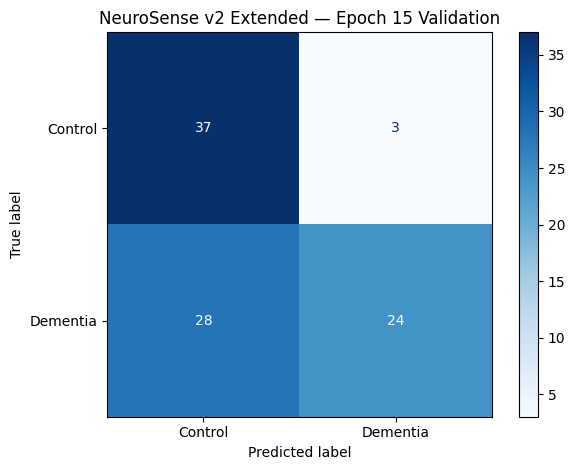

Saved report: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/epoch15_validation_report.txt


In [ ]:

import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

metrics = ckpt["val_metrics"]
print("Saved checkpoint metrics:")
print(json.dumps(metrics, indent=2))

# Reconstruct counts from the known validation class sizes.
n_control = 40
n_dementia = 52

tp_control = round(
    metrics["recall_control"] * n_control
)
tp_dementia = round(
    metrics["recall_dementia"] * n_dementia
)

cm = np.array([
    [tp_control, n_control - tp_control],
    [n_dementia - tp_dementia, tp_dementia]
])

assert cm.sum() == 92
assert abs(np.trace(cm) / 92 - metrics["accuracy"]) < 0.001

y_true = [0] * n_control + [1] * n_dementia
y_pred = (
    [0] * cm[0, 0] + [1] * cm[0, 1] +
    [0] * cm[1, 0] + [1] * cm[1, 1]
)

report = classification_report(
    y_true, y_pred,
    target_names=["Control", "Dementia"],
    digits=4
)

print("\nConfusion matrix:\n", cm)
print("\nClassification report:\n", report)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Control", "Dementia"]
)
display.plot(cmap="Blues", values_format="d")
plt.title("NeuroSense v2 Extended — Epoch 15 Validation")
plt.tight_layout()
plt.savefig(
    extended / "epoch15_validation_confusion_matrix.png",
    dpi=200
)
plt.show()

report_path = extended / "epoch15_validation_report.txt"
report_path.write_text(
    f"Epoch: 15\nMetrics: {metrics}\n"
    f"Confusion matrix:\n{cm}\n\n{report}",
    encoding="utf-8"
)

print("Saved report:", report_path)

In [ ]:

from pathlib import Path
import ast

path = Path(
    "/content/NeuroSense_Colab/"
    "speech_model/training/train_speech_encoder.py"
)

source = path.read_text(encoding="utf-8")
tree = ast.parse(source)
lines = source.splitlines()

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name in {"evaluate", "compute_metrics"}:
            print(f"\n{'=' * 15} {node.name} {'=' * 15}")
            print("\n".join(lines[node.lineno - 1:node.end_lineno]))


=============== compute_metrics ===============
def compute_metrics(preds: list[int], targets: list[int]) -> dict:
    """Accuracy, per-class recall, and balanced accuracy."""
    n = len(targets)
    if n == 0:
        return {"accuracy": 0.0, "balanced_acc": 0.0, "recall_control": 0.0, "recall_dementia": 0.0}

    correct = sum(p == t for p, t in zip(preds, targets))
    accuracy = correct / n

    recalls = []
    for cls in [0, 1]:
        tp = sum(1 for p, t in zip(preds, targets) if p == cls and t == cls)
        fn = sum(1 for p, t in zip(preds, targets) if p != cls and t == cls)
        denom = tp + fn
        recalls.append(tp / denom if denom > 0 else 0.0)

    balanced_acc = sum(recalls) / len(recalls)
    return {
        "accuracy":        round(accuracy, 4),
        "balanced_acc":    round(balanced_acc, 4),
        "recall_control":  round(recalls[0], 4),
        "recall_dementia": round(recalls[1], 4),
    }

=============== evaluate ===============
def evaluate(model,

In [ ]:

%cd /content/NeuroSense_Colab

import sys
import csv
from pathlib import Path
import torch
import speech_model.training.train_speech_encoder as trainer

extended = Path(
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_Checkpoints_v2/extended_training"
)

checkpoint = extended / "best_model.pt"
assert checkpoint.is_file(), "Epoch-15 checkpoint not found."

saved = torch.load(
    checkpoint, map_location="cpu", weights_only=False
)
assert saved["epoch"] == 15, "Expected the epoch-15 checkpoint."

records = []

# Capture probabilities using the existing validation loader.
original_evaluate = trainer.evaluate

def evaluate_with_probabilities(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    predictions = []
    targets = []

    with torch.no_grad():
        for batch in loader:
            acoustic = batch["acoustic_raw"].to(device)
            affective = batch["affective_raw"].to(device)
            labels = batch["label"].to(device)

            logits, _, _, _ = model(acoustic, affective)
            probabilities = torch.softmax(logits, dim=-1)[:, 1]
            predicted = logits.argmax(dim=-1)

            loss = criterion(logits, labels)
            total_loss += loss.item()

            predictions.extend(predicted.cpu().tolist())
            targets.extend(labels.cpu().tolist())

            for actual, probability in zip(
                labels.cpu().tolist(),
                probabilities.cpu().tolist()
            ):
                records.append({
                    "actual_label": int(actual),
                    "prob_dementia": float(probability)
                })

    return (
        total_loss / max(1, len(loader)),
        predictions,
        targets
    )

original_argv = sys.argv[:]

try:
    trainer.evaluate = evaluate_with_probabilities

    sys.argv = [
        "train_speech_encoder.py",
        "--train_csv",
        "v2_test_fixed_20260927/manifests/train_v2_fixed.csv",
        "--valid_csv",
        "v2_test_fixed_20260927/manifests/valid_v2_fixed.csv",
        "--test_csv",
        "speech_model/data/manifests/test.csv",
        "--data_root", "/content/data",
        "--output_dir", str(extended),
        "--batch_size", "4",
        "--device", "cuda",
        "--resume", str(checkpoint),
        "--evaluate_only"
    ]

    trainer.main()

finally:
    trainer.evaluate = original_evaluate
    sys.argv = original_argv

assert len(records) == 92, (
    f"Expected 92 validation predictions; got {len(records)}"
)

csv_path = extended / "epoch15_validation_probabilities.csv"

with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f, fieldnames=["actual_label", "prob_dementia"]
    )
    writer.writeheader()
    writer.writerows(records)

print("Saved:", csv_path)
print("Validation predictions:", len(records))

/content/NeuroSense_Colab
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : v2_test_fixed_20260927/manifests/train_v2_fixed.csv
  Valid Manifest   : v2_test_fixed_20260927/manifests/valid_v2_fixed.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt

[1/4] Pre-loading frozen encoder backbones onto target device...


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


[2/4] Loading manifests and initializing dataset loaders...
      Train samples: 365 | Valid samples: 92

[3/4] Constructing NeuroSenseClassifier and verifying gradient flow...
      Total trainable parameters: 657,410 / 657,410
      Trainable components: acoustic_proj, affective_proj, fusion_encoder, classifier
      Class weights: Control=1.061, Dementia=0.946

  Resuming checkpoint from /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt...
  Resumed successfully. Starting at epoch 16, previous best val_bal_acc=0.6933

  [Evaluate Only Mode]
  Validation Loss: 0.9488 | Metrics: {'accuracy': 0.663, 'balanced_acc': 0.6933, 'recall_control': 0.925, 'recall_dementia': 0.4615}
Saved: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/epoch15_validation_probabilities.csv
Validation predictions: 92


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

df = pd.read_csv(csv_path)

y_true = df["actual_label"].to_numpy()
prob = df["prob_dementia"].to_numpy()

results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    y_pred = (prob >= threshold).astype(int)

    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    results.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "control_recall": recall_score(
            y_true, y_pred, pos_label=0
        ),
        "dementia_recall": recall_score(
            y_true, y_pred, pos_label=1
        ),
        "dementia_precision": precision_score(
            y_true, y_pred, pos_label=1,
            zero_division=0
        ),
        "dementia_f1": f1_score(
            y_true, y_pred, pos_label=1,
            zero_division=0
        ),
        "false_negatives": int(cm[1, 0])
    })

threshold_df = pd.DataFrame(results)

cm_display(
    threshold_df.round(3).set_index("threshold")
)

ax = threshold_df.plot(
    x="threshold",
    y=[
        "balanced_accuracy",
        "control_recall",
        "dementia_recall"
    ],
    marker="o",
    figsize=(10, 5),
    grid=True
)

ax.axvline(
    0.50, linestyle="--",
    label="Default threshold"
)
ax.set_ylabel("Score")
ax.set_xlabel("Dementia probability threshold")
ax.set_title("Epoch 15 — Validation threshold analysis")
ax.legend()
plt.tight_layout()

figure_path = (
    extended / "epoch15_validation_threshold_analysis.png"
)
plt.savefig(figure_path, dpi=200)
plt.show()

table_path = extended / "epoch15_threshold_results.csv"
threshold_df.to_csv(table_path, index=False)

print("Saved table:", table_path)
print("Saved chart:", figure_path)

NameError: name 'cm_display' is not defined

In [ ]:
from IPython.display import display

display(threshold_df.round(3).set_index("threshold"))


,accuracy,balanced_accuracy,control_recall,dementia_recall,dementia_precision,dementia_f1,false_negatives
threshold,,,,,,,
0.10,0.620,0.594,0.400,0.788,0.631,0.701,11
0.15,0.674,0.660,0.550,0.769,0.690,0.727,12
0.20,0.630,0.627,0.600,0.654,0.680,0.667,18
0.25,0.620,0.620,0.625,0.615,0.681,0.646,20
0.30,0.641,0.651,0.725,0.577,0.732,0.645,22
0.35,0.641,0.657,0.775,0.538,0.757,0.629,24
0.40,0.663,0.685,0.850,0.519,0.818,0.635,25
0.45,0.663,0.690,0.900,0.481,0.862,0.617,27
0.50,0.663,0.693,0.925,0.462,0.889,0.608,28


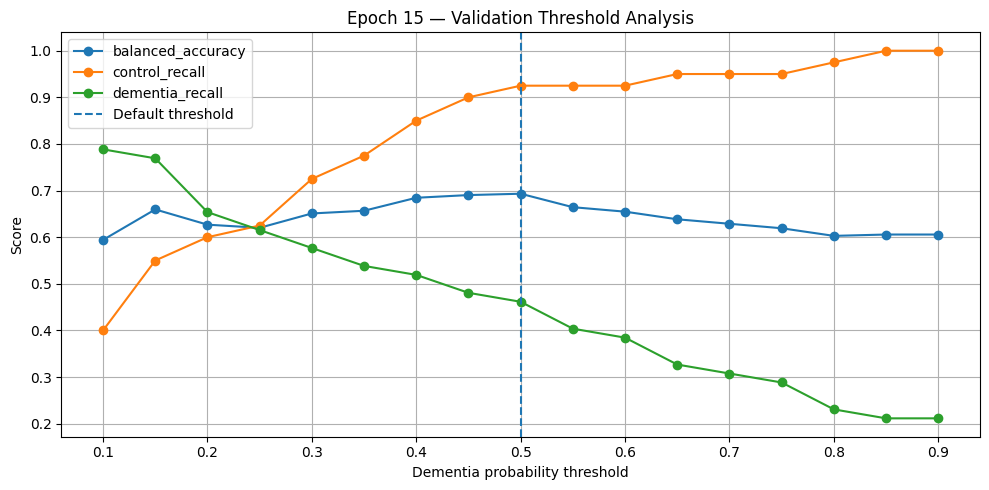

Saved table: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/epoch15_threshold_results.csv
Saved chart: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/epoch15_validation_threshold_analysis.png


In [ ]:
import matplotlib.pyplot as plt

ax = threshold_df.plot(
    x="threshold",
    y=[
        "balanced_accuracy",
        "control_recall",
        "dementia_recall"
    ],
    marker="o",
    figsize=(10, 5),
    grid=True
)

ax.axvline(
    0.50,
    linestyle="--",
    label="Default threshold"
)

ax.set_ylabel("Score")
ax.set_xlabel("Dementia probability threshold")
ax.set_title("Epoch 15 — Validation Threshold Analysis")
ax.legend()

plt.tight_layout()

figure_path = extended / "epoch15_validation_threshold_analysis.png"
plt.savefig(figure_path, dpi=200)
plt.show()

table_path = extended / "epoch15_threshold_results.csv"
threshold_df.to_csv(table_path, index=False)

print("Saved table:", table_path)
print("Saved chart:", figure_path)

In [ ]:

from pathlib import Path
import ast

root = Path("/content/NeuroSense_Colab")
training_script = root / "speech_model/training/train_speech_encoder.py"

assert training_script.is_file(), "Training script not found"

source = training_script.read_text(encoding="utf-8")
tree = ast.parse(source)
lines = source.splitlines()

print("=== MODEL IMPORTS ===")
for node in tree.body:
    if isinstance(node, (ast.Import, ast.ImportFrom)):
        segment = ast.get_source_segment(source, node)
        if any(term in segment.lower() for term in [
            "model", "classifier", "dataset", "torch"
        ]):
            print(segment)

print("\n=== MODEL AND OPTIMIZER SETUP ===")
for i, line in enumerate(lines):
    if any(term in line for term in [
        "NeuroSenseClassifier(",
        "AdamW(",
        "DataLoader(",
        "scheduler ="
    ]):
        start = max(0, i - 4)
        end = min(len(lines), i + 9)
        print(f"\nLines {start + 1}–{end}:")
        print("\n".join(
            f"{j + 1:04d}: {lines[j]}"
            for j in range(start, end)
        ))

print("\n=== CLASSIFIER DEFINITION ===")
for path in (root / "speech_model").rglob("*.py"):
    content = path.read_text(encoding="utf-8")
    parsed = ast.parse(content)
    for node in ast.walk(parsed):
        if isinstance(node, ast.ClassDef) and (
            node.name == "NeuroSenseClassifier"
        ):
            print("File:", path.relative_to(root))
            print(ast.get_source_segment(content, node))

AssertionError: Training script not found

In [ ]:

from pathlib import Path

print("Project folder exists:",
      Path("/content/NeuroSense_Colab").exists())

print("Audio folder exists:",
      Path("/content/data/raw").exists())

print("Drive mounted:",
      Path("/content/drive/MyDrive").exists())

print("\nFiles currently in /content:")
for p in Path("/content").iterdir():
    print(" ", p.name)

Project folder exists: False
Audio folder exists: False
Drive mounted: False

Files currently in /content:
  .config
  sample_data


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

for folder in [
    drive_root / "NeuroSense",
    drive_root / "NeuroSense_Backups",
]:
    print(f"\n{folder}")
    if folder.exists():
        for item in folder.iterdir():
            print(" ", item.name)
    else:
        print("Folder not found")

checkpoint_dir = (
    drive_root / "NeuroSense/NeuroSense_Checkpoints_v2"
)

print("\nCompleted v2 files:")
for name in [
    "best_model.pt",
    "latest_checkpoint.pt",
    "final_test_evaluation_v2.txt",
    "extended_training/best_model.pt",
    "extended_training/latest_checkpoint.pt",
    "extended_training/epoch15_validation_report.txt",
    "extended_training/epoch15_threshold_results.csv",
]:
    path = checkpoint_dir / name
    print("FOUND" if path.is_file() else "MISSING", name)


/content/drive/MyDrive/NeuroSense
  NeuroSense_Audio_Data.zip
  NeuroSense_Colab_Project.zip
  NeuroSense_Colab_v2_test_fixed_20260927_final.zip
  NeuroSense_v2_Colab_ready_fixed.zip
  NeuroSense_Checkpoints_v2

/content/drive/MyDrive/NeuroSense_Backups
  20260926_212515
  v2_completed_20260927_111714

Completed v2 files:
FOUND best_model.pt
FOUND latest_checkpoint.pt
FOUND final_test_evaluation_v2.txt
FOUND extended_training/best_model.pt
FOUND extended_training/latest_checkpoint.pt
FOUND extended_training/epoch15_validation_report.txt
FOUND extended_training/epoch15_threshold_results.csv


In [ ]:

from pathlib import Path
import zipfile

drive_root = Path("/content/drive/MyDrive/NeuroSense")
project_zip = drive_root / "NeuroSense_v2_Colab_ready_fixed.zip"

assert project_zip.is_file(), "Project ZIP not found"

with zipfile.ZipFile(project_zip) as z:
    names = z.namelist()
    print("ZIP entries:", len(names))
    print("First entries:", names[:10])

    # Extract into temporary Colab storage.
    z.extractall("/content")

# Find the restored training script, regardless of ZIP layout.
matches = list(
    Path("/content").rglob(
        "speech_model/training/train_speech_encoder.py"
    )
)

print("\nTraining scripts found:")
for path in matches:
    print(path)

assert matches, "Training script missing from extracted ZIP"

project = matches[0].parents[2]
print("\nRestored project:", project)

ZIP entries: 217
First entries: ['NeuroSense_Colab/', 'NeuroSense_Colab/speech_model/', 'NeuroSense_Colab/v2_test_fixed_20260927/', 'NeuroSense_Colab/requirements.txt', 'NeuroSense_Colab/NeuroSense_Colab.ipynb', 'NeuroSense_Colab/speech_model/__pycache__/', 'NeuroSense_Colab/speech_model/acoustic/', 'NeuroSense_Colab/speech_model/cache/', 'NeuroSense_Colab/speech_model/configs/', 'NeuroSense_Colab/speech_model/data/']

Training scripts found:
/content/NeuroSense_Colab/speech_model/training/train_speech_encoder.py

Restored project: /content/NeuroSense_Colab


In [ ]:

from pathlib import Path
import zipfile

audio_zip = Path(
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_Audio_Data.zip"
)

assert audio_zip.is_file(), "Audio ZIP not found"

with zipfile.ZipFile(audio_zip) as z:
    print("Audio archive entries:", len(z.namelist()))
    print("First entries:", z.namelist()[:5])
    z.extractall("/content/data")

print("Audio extraction completed.")

Audio archive entries: 545
First entries: ['raw/controled/002-0.wav', 'raw/controled/002-1.wav', 'raw/controled/002-2.wav', 'raw/controled/002-3.wav', 'raw/controled/006-2.wav']
Audio extraction completed.


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU available. Stop before training.")

CUDA available: True
GPU: Tesla T4


In [ ]:

from pathlib import Path

required = {
    "Training script":
        project / "speech_model/training/train_speech_encoder.py",
    "V2 training manifest":
        project / "v2_test_fixed_20260927/manifests/train_v2_fixed.csv",
    "V2 validation manifest":
        project / "v2_test_fixed_20260927/manifests/valid_v2_fixed.csv",
    "Frozen test manifest":
        project / "speech_model/data/manifests/test.csv",
    "Epoch-15 checkpoint":
        Path("/content/drive/MyDrive/NeuroSense/"
             "NeuroSense_Checkpoints_v2/"
             "extended_training/best_model.pt")
}

for name, path in required.items():
    print(
        "PASS" if path.is_file() else "MISSING",
        name,
        "->",
        path
    )

audio_files = list(Path("/content/data").rglob("*.wav"))
print("\nExtracted WAV recordings:", len(audio_files))

assert all(path.is_file() for path in required.values())
assert len(audio_files) >= 526, "Audio extraction appears incomplete"

print("\nProject restoration verified.")

PASS Training script -> /content/NeuroSense_Colab/speech_model/training/train_speech_encoder.py
PASS V2 training manifest -> /content/NeuroSense_Colab/v2_test_fixed_20260927/manifests/train_v2_fixed.csv
PASS V2 validation manifest -> /content/NeuroSense_Colab/v2_test_fixed_20260927/manifests/valid_v2_fixed.csv
PASS Frozen test manifest -> /content/NeuroSense_Colab/speech_model/data/manifests/test.csv
PASS Epoch-15 checkpoint -> /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt

Extracted WAV recordings: 544

Project restoration verified.


In [ ]:

from pathlib import Path
import ast

root = Path("/content/NeuroSense_Colab")
training_script = root / "speech_model/training/train_speech_encoder.py"

assert training_script.is_file(), "Training script not found"

source = training_script.read_text(encoding="utf-8")
tree = ast.parse(source)
lines = source.splitlines()

print("=== MODEL IMPORTS ===")
for node in tree.body:
    if isinstance(node, (ast.Import, ast.ImportFrom)):
        segment = ast.get_source_segment(source, node)
        if any(term in segment.lower() for term in [
            "model", "classifier", "dataset", "torch"
        ]):
            print(segment)

print("\n=== MODEL AND OPTIMIZER SETUP ===")
for i, line in enumerate(lines):
    if any(term in line for term in [
        "NeuroSenseClassifier(",
        "AdamW(",
        "DataLoader(",
        "scheduler ="
    ]):
        start = max(0, i - 4)
        end = min(len(lines), i + 9)
        print(f"\nLines {start + 1}–{end}:")
        print("\n".join(
            f"{j + 1:04d}: {lines[j]}"
            for j in range(start, end)
        ))

print("\n=== CLASSIFIER DEFINITION ===")
for path in (root / "speech_model").rglob("*.py"):
    content = path.read_text(encoding="utf-8")
    parsed = ast.parse(content)
    for node in ast.walk(parsed):
        if isinstance(node, ast.ClassDef) and (
            node.name == "NeuroSenseClassifier"
        ):
            print("File:", path.relative_to(root))
            print(ast.get_source_segment(content, node))

=== MODEL IMPORTS ===
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from speech_model.preprocessing.audio import load_audio, trim_audio
from speech_model.acoustic.wav2vec_encoder import extract_raw_features as extract_acoustic_raw, _load as load_acoustic
from speech_model.transcription.whisper_transcriber import transcribe
from speech_model.sentiment.sentiment_encoder import extract_raw_features as extract_sentiment_raw, _load as load_sentiment
from speech_model.fusion.speech_fusion import SpeechFusionEncoder
from speech_model.data.resolve_paths import resolve_audio_path

=== MODEL AND OPTIMIZER SETUP ===

Lines 119–131:
0119: 
0120:     def forward(self, speech_emb: torch.Tensor) -> torch.Tensor:
0121:         return self.head(speech_emb)
0122: 
0123: class NeuroSenseClassifier(nn.Module):
0124:     """End-to-End Trainable Classifier Module.
0125:     Combines trainable projection heads, speech fusion MLP, and dementia classifier.
0126:     """
01

In [ ]:

from pathlib import Path
import ast

root = Path("/content/NeuroSense_Colab")
if not (root / "speech_model").is_dir():
    root = project  # Project path found during restoration

original = root / "speech_model/training/train_speech_encoder.py"
destination = root / "speech_model/training/train_ablation.py"

source = original.read_text(encoding="utf-8")
tree = ast.parse(source)

classifier = next(
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
    and node.name == "NeuroSenseClassifier"
)

replacement = '''
class NeuroSenseClassifier(nn.Module):
    """Single-branch ablation with the original fusion architecture."""

    def __init__(
        self, acoustic_dim=256, text_dim=256,
        fusion_hidden_dim=256, fusion_output_dim=256,
        num_classes=2, dropout=0.3
    ):
        super().__init__()
        import os

        self.mode = os.environ.get("NEUROSENSE_ABLATION")
        assert self.mode in ("acoustic", "affective")

        self.acoustic_proj = nn.Linear(1024, acoustic_dim)
        self.affective_proj = nn.Linear(768, text_dim)

        self.fusion_encoder = SpeechFusionEncoder(
            hidden_dim=fusion_hidden_dim,
            output_dim=fusion_output_dim
        )
        self.classifier = DementiaClassifier(
            fusion_output_dim=fusion_output_dim,
            num_classes=num_classes,
            dropout=dropout
        )

        # Freeze the projection for the unused input branch.
        inactive = (
            self.affective_proj if self.mode == "acoustic"
            else self.acoustic_proj
        )
        for parameter in inactive.parameters():
            parameter.requires_grad = False

    def forward(self, acoustic_raw, affective_raw):
        if self.mode == "acoustic":
            acoustic_emb = self.acoustic_proj(acoustic_raw)
            affective_emb = torch.zeros(
                acoustic_raw.shape[0], 256,
                device=acoustic_raw.device,
                dtype=acoustic_raw.dtype
            )
        else:
            affective_emb = self.affective_proj(affective_raw)
            acoustic_emb = torch.zeros(
                affective_raw.shape[0], 256,
                device=affective_raw.device,
                dtype=affective_raw.dtype
            )

        speech_emb = self.fusion_encoder(
            acoustic_emb, affective_emb
        )
        logits = self.classifier(speech_emb)

        return logits, speech_emb, acoustic_emb, affective_emb
'''

lines = source.splitlines(keepends=True)
lines[classifier.lineno - 1:classifier.end_lineno] = [
    replacement + "\n"
]

destination.write_text("".join(lines), encoding="utf-8")

# Verify the new script is syntactically valid.
compile(destination.read_text(), str(destination), "exec")

print("Created:", destination)
print("Original training script remains unchanged.")

Created: /content/NeuroSense_Colab/speech_model/training/train_ablation.py
Original training script remains unchanged.


In [ ]:

%cd /content/NeuroSense_Colab

!NEUROSENSE_ABLATION=acoustic python -m speech_model.training.train_ablation \
  --train_csv v2_test_fixed_20260927/manifests/train_v2_fixed.csv \
  --valid_csv v2_test_fixed_20260927/manifests/valid_v2_fixed.csv \
  --test_csv speech_model/data/manifests/test.csv \
  --data_root /content/data \
  --output_dir /content/drive/MyDrive/NeuroSense/NeuroSense_Ablation/acoustic_only \
  --epochs 20 \
  --batch_size 4 \
  --lr 0.001 \
  --patience 5 \
  --seed 42 \
  --device cuda

/content/NeuroSense_Colab
PHASE E -- NeuroSense Supervised Training Pipeline
  Device           : cuda
  Train Manifest   : v2_test_fixed_20260927/manifests/train_v2_fixed.csv
  Valid Manifest   : v2_test_fixed_20260927/manifests/valid_v2_fixed.csv
  Test Manifest    : speech_model/data/manifests/test.csv
  Output Directory : /content/drive/MyDrive/NeuroSense/NeuroSense_Ablation/acoustic_only
  Epochs           : 20
  Batch Size       : 4
  Learning Rate    : 0.001
  Random Seed      : 42
  Smoke Test       : False
  One Epoch        : False
  Resume Checkpoint: None

[1/4] Pre-loading frozen encoder backbones onto target device...
preprocessor_config.json: 100% 212/212 [00:00<00:00, 1.10MB/s]
config.json: 100% 1.57k/1.57k [00:00<00:00, 4.01MB/s]

pytorch_model.bin: downloading bytes:  10% 124M/1.27G [00:01<00:06, 174MB/s, 9.52MB/s  ] 
pytorch_model.bin: downloading bytes:  12% 151M/1.27G [00:01<00:07, 156MB/s, 13.1MB/s  ]
pytorch_model.bin: downloading bytes:  14% 173M/1.27G [00:01<00

In [ ]:

from pathlib import Path
import ast

root = Path("/content/NeuroSense_Colab")

# Use the restored project location if the ZIP had another layout.
if not (root / "speech_model").exists():
    root = project

training_file = (
    root / "speech_model/training/train_speech_encoder.py"
)
fusion_file = (
    root / "speech_model/fusion/speech_fusion.py"
)

assert training_file.is_file(), "Training script not found"
assert fusion_file.is_file(), "Fusion module not found"

def show_definition(path, names):
    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            if node.name in names:
                print(f"\n{'=' * 60}")
                print(f"{path.name}: {node.name}")
                print("=" * 60)
                print(ast.get_source_segment(source, node))

show_definition(
    training_file,
    {"SpeechDataset", "evaluate"}
)

show_definition(
    fusion_file,
    {"SpeechFusionEncoder"}
)

print("\n=== EVALUATION AND CHECKPOINT CODE ===")
source = training_file.read_text(encoding="utf-8")
lines = source.splitlines()

for i, line in enumerate(lines):
    if (
        "args.evaluate_only" in line
        or "torch.load(" in line
        or "model.load_state_dict(" in line
    ):
        start = max(0, i - 3)
        end = min(len(lines), i + 9)

        print(f"\nLines {start + 1}–{end}")
        print("\n".join(
            f"{j + 1:04d}: {lines[j]}"
            for j in range(start, end)
        ))


train_speech_encoder.py: SpeechDataset
class SpeechDataset(Dataset):
    """Dataset reading manifest CSVs and extracting raw backbone features lazily.
    """
    def __init__(self, csv_path: str | Path, device: torch.device, data_root: str = None):
        self.device = device
        self.records = []
        csv_path = Path(csv_path)
        if not csv_path.exists():
            raise FileNotFoundError(f"Manifest file not found: {csv_path}")

        with open(csv_path, newline="", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                resolved_path = resolve_audio_path(row["audio_path"], data_root=data_root)
                if not os.path.isfile(resolved_path):
                    continue
                if row["label"] not in LABEL_MAP:
                    continue
                row["audio_path"] = resolved_path
                self.records.append(row)

        if not self.records:
            raise RuntimeError(f"No valid audio records found in {csv

In [ ]:

from pathlib import Path
import pandas as pd

drive = Path("/content/drive/MyDrive/NeuroSense")

checkpoint = (
    drive
    / "NeuroSense_Checkpoints_v2"
    / "extended_training"
    / "best_model.pt"
)

validation_csv = (
    root
    / "v2_test_fixed_20260927"
    / "manifests"
    / "valid_v2_fixed.csv"
)

assert checkpoint.is_file(), "Epoch-15 checkpoint not found"
assert validation_csv.is_file(), "Validation manifest not found"

validation = pd.read_csv(validation_csv)

print("Checkpoint:", checkpoint)
print("Validation recordings:", len(validation))
print("Manifest columns:", validation.columns.tolist())
print("\nClass distribution:")

if "label" in validation.columns:
    print(validation["label"].value_counts())

assert len(validation) == 92, (
    "Expected the original 92-recording validation set"
)

output_dir = (
    drive
    / "NeuroSense_Checkpoints_v2"
    / "feature_ablation"
)
output_dir.mkdir(parents=True, exist_ok=True)

print("\nResults will be saved to:", output_dir)
print("No training will be performed.")

Checkpoint: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt
Validation recordings: 92
Manifest columns: ['audio_path', 'label', 'participant_id', 'session', 'filename_has_N', 'ext', 'file_bytes', 'sha256', 'duration_s', 'sample_rate', 'channels', 'n_frames', 'readable', 'decode_error', 'is_copy_v2', 'label_conflict', 'status', 'exclude_reason', 'participant_key', 'source_provenance']

Class distribution:
label
dementia    52
control     40
Name: count, dtype: int64

Results will be saved to: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/feature_ablation
No training will be performed.


In [ ]:

from pathlib import Path
import sys
import torch

root = Path("/content/NeuroSense_Colab")
if not (root / "speech_model").is_dir():
    root = project

sys.path.insert(0, str(root))

drive = Path("/content/drive/MyDrive/NeuroSense")
validation_csv = (
    root / "v2_test_fixed_20260927"
    / "manifests/valid_v2_fixed.csv"
)
checkpoint_path = (
    drive / "NeuroSense_Checkpoints_v2"
    / "extended_training/best_model.pt"
)
output_dir = (
    drive / "NeuroSense_Checkpoints_v2"
    / "feature_ablation"
)
output_dir.mkdir(parents=True, exist_ok=True)

assert validation_csv.is_file(), "Validation CSV missing"
assert checkpoint_path.is_file(), "Epoch-15 checkpoint missing"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Project:", root)
print("Device:", device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Output folder:", output_dir)

assert checkpoint["epoch"] == 15, (
    "Expected the extended epoch-15 checkpoint"
)

Project: /content/NeuroSense_Colab
Device: cuda
Checkpoint epoch: 15
Output folder: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/feature_ablation


In [ ]:

import hashlib
import json
import torch

from speech_model.training.train_speech_encoder import (
    SpeechDataset,
)

dataset = SpeechDataset(
    validation_csv,
    device=device,
    data_root="/content/data"
)

assert len(dataset) == 92, (
    f"Expected 92 recordings, found {len(dataset)}"
)

cache_dir = output_dir / "validation_feature_cache"
cache_dir.mkdir(parents=True, exist_ok=True)

# Save the exact manifest identity alongside the cache.
manifest_hash = hashlib.sha256(
    validation_csv.read_bytes()
).hexdigest()

metadata_path = cache_dir / "metadata.json"

if metadata_path.exists():
    metadata = json.loads(metadata_path.read_text())
    assert metadata["manifest_sha256"] == manifest_hash, (
        "The validation manifest changed. "
        "Do not reuse this cache."
    )
else:
    metadata_path.write_text(json.dumps({
        "manifest_sha256": manifest_hash,
        "record_count": len(dataset),
        "source": str(validation_csv)
    }, indent=2))

for index in range(len(dataset)):
    cache_file = cache_dir / f"record_{index:03d}.pt"

    if cache_file.exists():
        print(
            f"[{index + 1}/{len(dataset)}] Cached",
            flush=True
        )
        continue

    # Runs frozen Wav2Vec2, Whisper and emotion extraction.
    sample = dataset[index]

    item = {
        "acoustic_raw": sample["acoustic_raw"].cpu(),
        "affective_raw": sample["affective_raw"].cpu(),
        "label": int(sample["label"]),
        "pid": sample["pid"],
        "path": sample["path"],
    }

    # Write atomically to avoid incomplete cache files.
    temporary = cache_file.with_suffix(".tmp")
    torch.save(item, temporary)
    temporary.replace(cache_file)

    print(
        f"[{index + 1}/{len(dataset)}] Saved",
        flush=True
    )

print("\nAll validation features cached.")

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.weight             | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[1/92] Saved
[2/92] Saved
[3/92] Saved
[4/92] Saved
[5/92] Saved
[6/92] Saved
[7/92] Saved
[8/92] Saved
[9/92] Saved
[10/92] Saved
[11/92] Saved
[12/92] Saved
[13/92] Saved
[14/92] Saved
[15/92] Saved
[16/92] Saved
[17/92] Saved
[18/92] Saved
[19/92] Saved
[20/92] Saved
[21/92] Saved
[22/92] Saved
[23/92] Saved
[24/92] Saved
[25/92] Saved
[26/92] Saved
[27/92] Saved
[28/92] Saved
[29/92] Saved
[30/92] Saved
[31/92] Saved
[32/92] Saved
[33/92] Saved
[34/92] Saved
[35/92] Saved
[36/92] Saved
[37/92] Saved
[38/92] Saved
[39/92] Saved
[40/92] Saved
[41/92] Saved
[42/92] Saved
[43/92] Saved
[44/92] Saved
[45/92] Saved
[46/92] Saved
[47/92] Saved
[48/92] Saved
[49/92] Saved
[50/92] Saved
[51/92] Saved
[52/92] Saved
[53/92] Saved
[54/92] Saved
[55/92] Saved
[56/92] Saved
[57/92] Saved
[58/92] Saved
[59/92] Saved
[60/92] Saved
[61/92] Saved
[62/92] Saved
[63/92] Saved
[64/92] Saved
[65/92] Saved
[66/92] Saved
[67/92] Saved
[68/92] Saved
[69/92] Saved
[70/92] Saved
[71/92] Saved
[72/92] Saved
[

In [ ]:

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

from speech_model.training.train_speech_encoder import (
    NeuroSenseClassifier,
)

model = NeuroSenseClassifier(
    acoustic_dim=256,
    text_dim=256,
    fusion_hidden_dim=256,
    fusion_output_dim=256,
    num_classes=2,
    dropout=0.3,
).to(device)

model.load_state_dict(checkpoint["model_state"])
model.eval()

# Load features in the original manifest order.
records = [
    torch.load(
        cache_dir / f"record_{i:03d}.pt",
        map_location="cpu",
        weights_only=False
    )
    for i in range(92)
]

acoustic = torch.stack([
    r["acoustic_raw"].reshape(-1) for r in records
]).to(device)

affective = torch.stack([
    r["affective_raw"].reshape(-1) for r in records
]).to(device)

labels = np.array([r["label"] for r in records])

assert acoustic.shape == (92, 1024)
assert affective.shape == (92, 768)
assert set(labels.tolist()) == {0, 1}

@torch.inference_mode()
def predict_condition(mode, batch_size=8):
    all_predictions = []
    all_probabilities = []

    for start in range(0, len(records), batch_size):
        a = acoustic[start:start + batch_size]
        e = affective[start:start + batch_size]

        a_emb = model.acoustic_proj(a)
        e_emb = model.affective_proj(e)

        if mode == "acoustic_only":
            e_emb = torch.zeros_like(e_emb)
        elif mode == "affective_only":
            a_emb = torch.zeros_like(a_emb)
        elif mode != "fusion":
            raise ValueError(mode)

        fused = model.fusion_encoder(a_emb, e_emb)
        logits = model.classifier(fused)
        probabilities = torch.softmax(logits, dim=-1)

        all_predictions.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )
        all_probabilities.extend(
            probabilities[:, 1].cpu().tolist()
        )

    return (
        np.array(all_predictions),
        np.array(all_probabilities)
    )

results = []
predictions = pd.DataFrame({
    "participant_id": [r["pid"] for r in records],
    "actual_label": labels,
})

for mode in [
    "fusion",
    "acoustic_only",
    "affective_only",
]:
    predicted, probabilities = predict_condition(mode)

    cm = confusion_matrix(
        labels, predicted, labels=[0, 1]
    )
    control_recall = cm[0, 0] / cm[0].sum()
    dementia_recall = cm[1, 1] / cm[1].sum()

    results.append({
        "condition": mode,
        "accuracy": accuracy_score(labels, predicted),
        "balanced_accuracy": balanced_accuracy_score(
            labels, predicted
        ),
        "control_recall": control_recall,
        "dementia_recall": dementia_recall,
        "false_positives": int(cm[0, 1]),
        "false_negatives": int(cm[1, 0]),
    })

    predictions[f"{mode}_prediction"] = predicted
    predictions[f"{mode}_p_dementia"] = probabilities

    print(f"\n{mode.upper()}")
    print("Confusion matrix:")
    print(cm)

results_df = pd.DataFrame(results)

results_df.to_csv(
    output_dir / "epoch15_feature_ablation_results.csv",
    index=False
)
predictions.to_csv(
    output_dir / "epoch15_feature_ablation_predictions.csv",
    index=False
)

print("\n=== COMPARISON ===")
print(results_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

# The unmodified fusion condition should reproduce
# the original epoch-15 validation results.
fusion = results_df.iloc[0]
assert abs(fusion["accuracy"] - 61 / 92) < 1e-6, (
    "Baseline accuracy differs from the saved report. "
    "Check feature extraction and checkpoint identity."
)
assert abs(
    fusion["balanced_accuracy"] - 0.6933
) < 0.001, (
    "Baseline balanced accuracy differs from "
    "the saved epoch-15 report."
)

print("\nBaseline reproduced successfully.")
print("Results saved to:", output_dir)


FUSION
Confusion matrix:
[[37  3]
 [28 24]]

ACOUSTIC_ONLY
Confusion matrix:
[[40  0]
 [52  0]]

AFFECTIVE_ONLY
Confusion matrix:
[[36  4]
 [28 24]]

=== COMPARISON ===
     condition  accuracy  balanced_accuracy  control_recall  dementia_recall  false_positives  false_negatives
        fusion    0.6630             0.6933          0.9250           0.4615                3               28
 acoustic_only    0.4348             0.5000          1.0000           0.0000                0               52
affective_only    0.6522             0.6808          0.9000           0.4615                4               28

Baseline reproduced successfully.
Results saved to: /content/drive/MyDrive/NeuroSense/NeuroSense_Checkpoints_v2/feature_ablation


In [ ]:

import pandas as pd
import numpy as np

csv_path = (
    "/content/drive/MyDrive/NeuroSense/"
    "NeuroSense_Checkpoints_v2/feature_ablation/"
    "epoch15_feature_ablation_predictions.csv"
)

df = pd.read_csv(csv_path)

for mode in ["fusion", "acoustic_only", "affective_only"]:
    col = f"{mode}_p_dementia"

    print(f"\n{mode.upper()}")
    print(
        df.groupby("actual_label")[col]
        .agg(["count", "mean", "median", "min", "max"])
        .round(4)
    )

    for label, name in [(0, "Control"), (1, "Dementia")]:
        values = df.loc[df.actual_label == label, col]
        print(
            f"{name}: "
            f"{(values >= 0.4).sum()}/{len(values)} "
            "have dementia probability >= 0.40"
        )

print("\n=== PREDICTION AGREEMENT ===")
for mode in ["acoustic_only", "affective_only"]:
    matches = (
        df[f"{mode}_prediction"]
        == df["fusion_prediction"]
    ).sum()

    print(
        f"{mode}: {matches}/{len(df)} predictions "
        "match the fusion model"
    )


FUSION
              count    mean  median     min     max
actual_label                                       
0                40  0.2045  0.1224  0.0019  0.8354
1                52  0.4625  0.4219  0.0021  0.9975
Control: 6/40 have dementia probability >= 0.40
Dementia: 27/52 have dementia probability >= 0.40

ACOUSTIC_ONLY
              count    mean  median     min     max
actual_label                                       
0                40  0.2757  0.2868  0.2204  0.3119
1                52  0.2641  0.2561  0.2225  0.3133
Control: 0/40 have dementia probability >= 0.40
Dementia: 0/52 have dementia probability >= 0.40

AFFECTIVE_ONLY
              count    mean  median     min     max
actual_label                                       
0                40  0.2046  0.1149  0.0019  0.8939
1                52  0.4650  0.4225  0.0020  0.9975
Control: 6/40 have dementia probability >= 0.40
Dementia: 26/52 have dementia probability >= 0.40

=== PREDICTION AGREEMENT ===
acoustic_only:

In [ ]:
hi

NameError: name 'hi' is not defined

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

MYDRIVE = Path("/content/drive/MyDrive")

# Find the existing project ZIP
project_zips = list(MYDRIVE.rglob("NeuroSense_v2_Colab_ready_fixed.zip"))
assert project_zips, "NeuroSense_v2_Colab_ready_fixed.zip not found"

PROJECT_ZIP = project_zips[0]

# Find the existing audio ZIP
audio_zips = list(MYDRIVE.rglob("NeuroSense_Audio_Data.zip"))
assert audio_zips, "NeuroSense_Audio_Data.zip not found"

AUDIO_ZIP = audio_zips[0]

# Find the extended epoch-15 checkpoint
checkpoints = list(
    MYDRIVE.rglob("extended_training/best_model.pt")
)

assert checkpoints, "Extended epoch-15 best_model.pt not found"

EPOCH15_CKPT = checkpoints[0]

print("PROJECT ZIP :", PROJECT_ZIP)
print("AUDIO ZIP   :", AUDIO_ZIP)
print("EPOCH-15 CKPT:", EPOCH15_CKPT)

Mounted at /content/drive
PROJECT ZIP : /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_v2_Colab_ready_fixed.zip
AUDIO ZIP   : /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_Audio_Data.zip
EPOCH-15 CKPT: /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt


In [2]:
from pathlib import Path
import zipfile

PROJECT_ROOT = Path("/content/NeuroSense_Colab")

if PROJECT_ROOT.exists():
    print("Project already exists:", PROJECT_ROOT)
else:
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(PROJECT_ZIP) as z:
        assert z.testzip() is None, "Project ZIP failed integrity check"
        z.extractall(PROJECT_ROOT)

print("Project restored.")

# Find the actual project root if the ZIP added another folder level
matches = list(
    Path("/content").rglob(
        "speech_model/training/train_speech_encoder.py"
    )
)

assert matches, "Training script not found after extraction"

PROJECT_ROOT = matches[0].parents[2]

print("Using project:", PROJECT_ROOT)

Project restored.
Using project: /content/NeuroSense_Colab/NeuroSense_Colab


In [3]:
from pathlib import Path
import zipfile

DATA_ROOT = Path("/content/data")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Only extract if the WAV files are not already present
existing_wavs = list(DATA_ROOT.rglob("*.wav"))

if len(existing_wavs) < 526:
    print("Extracting audio...")
    with zipfile.ZipFile(AUDIO_ZIP) as z:
        z.extractall(DATA_ROOT)
else:
    print("Audio already extracted:", len(existing_wavs), "WAV files")

audio_files = list(DATA_ROOT.rglob("*.wav"))

print("Total extracted WAV files:", len(audio_files))
assert len(audio_files) >= 526, "Audio extraction appears incomplete"

Extracting audio...
Total extracted WAV files: 544


In [4]:
%cd /content/NeuroSense_Colab

%pip install -q -r requirements.txt

import torch
from pathlib import Path

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("CUDA is required for this evaluation.")

# Verify checkpoint identity
ckpt = torch.load(
    EPOCH15_CKPT,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint:", EPOCH15_CKPT)
print("Checkpoint epoch:", ckpt["epoch"])
print("Validation metrics:", ckpt.get("val_metrics"))

assert ckpt["epoch"] == 15, (
    f"Expected epoch 15 checkpoint, got epoch {ckpt['epoch']}"
)

# Verify frozen test manifest
TEST_CSV = (
    PROJECT_ROOT
    / "speech_model/data/manifests/test.csv"
)

assert TEST_CSV.is_file(), f"Frozen test manifest missing: {TEST_CSV}"

import pandas as pd

test_df = pd.read_csv(TEST_CSV)

print("\nFrozen test recordings:", len(test_df))
print("Class distribution:")
print(test_df["label"].value_counts())

assert len(test_df) == 69
assert (test_df["label"] == "control").sum() == 20
assert (test_df["label"] == "dementia").sum() == 49

print("\nEverything verified.")

/content/NeuroSense_Colab
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
CUDA available: True
GPU: Tesla T4

Checkpoint: /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt
Checkpoint epoch: 15
Validation metrics: {'accuracy': 0.663, 'balanced_acc': 0.6933, 'recall_control': 0.925, 'recall_dementia': 0.4615}

Frozen test recordings: 69
Class distribution:
label
dementia    49
control     20
Name: count, dtype: int64

Everything verified.


In [5]:
import subprocess
from pathlib import Path

%cd /content/NeuroSense_Colab

EXTENDED_DIR = EPOCH15_CKPT.parent
OUTPUT_FILE = EXTENDED_DIR / "final_test_evaluation_epoch15.txt"

command = [
    "python",
    "v2_test_fixed_20260927/train_speech_encoder_test_fixed.py",

    "--train_csv",
    "v2_test_fixed_20260927/manifests/train_v2_fixed.csv",

    "--valid_csv",
    "v2_test_fixed_20260927/manifests/valid_v2_fixed.csv",

    "--test_csv",
    "speech_model/data/manifests/test.csv",

    "--data_root",
    "/content/data",

    "--output_dir",
    str(EXTENDED_DIR),

    "--batch_size",
    "4",

    "--device",
    "cuda",

    "--resume",
    str(EPOCH15_CKPT),

    "--evaluate_only",
]

print("Running FINAL epoch-15 test evaluation...")
print("Checkpoint:", EPOCH15_CKPT)
print("Test recordings:", len(test_df))

with OUTPUT_FILE.open("w", encoding="utf-8") as f:
    result = subprocess.run(
        command,
        cwd=str(PROJECT_ROOT),
        stdout=f,
        stderr=subprocess.STDOUT,
        text=True
    )

output = OUTPUT_FILE.read_text(encoding="utf-8")

print("\n" + "=" * 70)
print(output[-15000:])
print("=" * 70)

print("\nExit code:", result.returncode)

assert result.returncode == 0, (
    "Evaluation failed. Check:\n" + str(OUTPUT_FILE)
)

print("\nFINAL ACOUSTIC EVALUATION COMPLETE")
print("Saved to:", OUTPUT_FILE)

/content/NeuroSense_Colab
Running FINAL epoch-15 test evaluation...
Checkpoint: /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/best_model.pt
Test recordings: 69


Loading weights: 100%|██████████| 422/422 [00:00<00:00, 16653.46it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 10676.41it/s]

In [8]:
# ============================================================
# EPOCH-15 ACOUSTIC TEST PROBABILITIES
# DIRECT INFERENCE — NO TRAINING, NO trainer.main()
# ============================================================

from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Find the actual speech_model package
# ------------------------------------------------------------

search_roots = [
    Path("/content/NeuroSense_Colab"),
    Path("/content/NeuroSense"),
    Path("/content"),
]

package_file = None

for root in search_roots:
    if root.exists():
        found = list(root.rglob("speech_model/__init__.py"))
        if found:
            package_file = found[0]
            break

assert package_file is not None, (
    "Could not find speech_model/__init__.py anywhere under /content"
)

PACKAGE_DIR = package_file.parent
PROJECT_ROOT = PACKAGE_DIR.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

os.chdir(PROJECT_ROOT)

print("speech_model:", PACKAGE_DIR)
print("Project root:", PROJECT_ROOT)

# ------------------------------------------------------------
# 2. Import EXACT classes used by the notebook
# ------------------------------------------------------------

from speech_model.training.train_speech_encoder import (
    SpeechDataset,
    NeuroSenseClassifier,
)

print("Import: PASS")

# ------------------------------------------------------------
# 3. Paths
# ------------------------------------------------------------

CHECKPOINT = Path(
    "/content/drive/MyDrive/"
    "NEUROSENSE(SPEECH AND STMT ANALYSIS)/"
    "NeuroSense/NeuroSense_Checkpoints_v2/"
    "extended_training/best_model.pt"
)

TEST_CSV = (
    PROJECT_ROOT /
    "speech_model/data/manifests/test.csv"
)

OUTPUT_CSV = (
    CHECKPOINT.parent /
    "epoch15_frozen_test_probabilities.csv"
)

assert CHECKPOINT.is_file(), CHECKPOINT
assert TEST_CSV.is_file(), TEST_CSV

# ------------------------------------------------------------
# 4. Verify epoch-15 checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint epoch:", checkpoint["epoch"])

assert checkpoint["epoch"] == 15

# ------------------------------------------------------------
# 5. Create EXACT frozen test dataset
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "CUDA is required."

test_dataset = SpeechDataset(
    TEST_CSV,
    device=device,
    data_root="/content/data",
)

print("Device:", device)
print("Test recordings:", len(test_dataset))

assert len(test_dataset) == 69

# ------------------------------------------------------------
# 6. Load EXACT epoch-15 model architecture
# ------------------------------------------------------------

model = NeuroSenseClassifier(
    acoustic_dim=256,
    text_dim=256,
    fusion_hidden_dim=256,
    fusion_output_dim=256,
    num_classes=2,
    dropout=0.3,
).to(device)

model.load_state_dict(
    checkpoint["model_state"]
)

model.eval()

print("Model loaded successfully.")

# ------------------------------------------------------------
# 7. DIRECT INFERENCE
# ------------------------------------------------------------

predictions = []
probabilities = []
labels = []
participant_ids = []
audio_paths = []

with torch.inference_mode():

    for i in range(len(test_dataset)):

        sample = test_dataset[i]

        acoustic = sample["acoustic_raw"]
        affective = sample["affective_raw"]

        # Ensure batch dimension
        if acoustic.ndim == 1:
            acoustic = acoustic.unsqueeze(0)

        if affective.ndim == 1:
            affective = affective.unsqueeze(0)

        logits, _, _, _ = model(
            acoustic,
            affective
        )

        prob = torch.softmax(
            logits,
            dim=-1
        )[0, 1].item()

        pred = int(
            logits.argmax(dim=-1).item()
        )

        predictions.append(pred)
        probabilities.append(prob)
        labels.append(int(sample["label"]))

        participant_ids.append(
            str(sample["pid"])
        )

        audio_paths.append(
            str(sample["path"])
        )

        print(
            f"\r[{i+1:02d}/69]",
            end=""
        )

print("\nInference complete.")

# ------------------------------------------------------------
# 8. Build prediction table
# ------------------------------------------------------------

result_df = pd.DataFrame({
    "audio_path": audio_paths,
    "participant_id": participant_ids,
    "actual_label": labels,
    "acoustic_probability": probabilities,
    "acoustic_prediction": predictions,
})

# ------------------------------------------------------------
# 9. Verify test set
# ------------------------------------------------------------

assert len(result_df) == 69
assert set(result_df["actual_label"]) == {0, 1}

print("\nRecording class counts:")
print(result_df["actual_label"].value_counts())

print(
    "\nUnique participants:",
    result_df["participant_id"].nunique()
)

# ------------------------------------------------------------
# 10. Save
# ------------------------------------------------------------

result_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("ACOUSTIC PROBABILITIES SAVED")
print("=" * 70)

print("File:", OUTPUT_CSV)
print("Rows:", len(result_df))

print("\nFirst 5 rows:")
print(result_df.head())

print("\nProbability range:")
print(
    f"{result_df['acoustic_probability'].min():.6f}"
    f" → "
    f"{result_df['acoustic_probability'].max():.6f}"
)

speech_model: /content/NeuroSense_Colab/NeuroSense_Colab/speech_model
Project root: /content/NeuroSense_Colab/NeuroSense_Colab
Import: PASS
Checkpoint epoch: 15
Device: cuda
Test recordings: 69
Model loaded successfully.


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_addmm)

In [9]:
# ============================================================
# FIXED INFERENCE LOOP — CPU → CUDA
# ============================================================

predictions = []
probabilities = []
labels = []
participant_ids = []
audio_paths = []

model.eval()

with torch.inference_mode():

    for i in range(len(test_dataset)):

        sample = test_dataset[i]

        # IMPORTANT: move features to the same device as model
        acoustic = sample["acoustic_raw"].to(device)
        affective = sample["affective_raw"].to(device)

        # Add batch dimension
        if acoustic.ndim == 1:
            acoustic = acoustic.unsqueeze(0)

        if affective.ndim == 1:
            affective = affective.unsqueeze(0)

        logits, _, _, _ = model(
            acoustic,
            affective
        )

        prob = torch.softmax(
            logits,
            dim=-1
        )[0, 1].item()

        pred = int(
            logits.argmax(dim=-1).item()
        )

        predictions.append(pred)
        probabilities.append(prob)
        labels.append(int(sample["label"]))

        participant_ids.append(
            str(sample["pid"])
        )

        audio_paths.append(
            str(sample["path"])
        )

        print(
            f"\r[{i+1:02d}/69]",
            end=""
        )

print("\nInference complete.")

# ------------------------------------------------------------
# Build result table
# ------------------------------------------------------------

result_df = pd.DataFrame({
    "audio_path": audio_paths,
    "participant_id": participant_ids,
    "actual_label": labels,
    "acoustic_probability": probabilities,
    "acoustic_prediction": predictions,
})

assert len(result_df) == 69

print("Unique participants:", result_df["participant_id"].nunique())

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

OUTPUT_CSV = (
    CHECKPOINT.parent /
    "epoch15_frozen_test_probabilities.csv"
)

result_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("ACOUSTIC PROBABILITIES SAVED")
print("=" * 70)

print("File:", OUTPUT_CSV)
print("Rows:", len(result_df))

print("\nPreview:")
print(result_df.head())

print("\nProbability range:")
print(
    f"{result_df['acoustic_probability'].min():.6f}"
    f" → "
    f"{result_df['acoustic_probability'].max():.6f}"
)

[69/69]
Inference complete.
Unique participants: 37

ACOUSTIC PROBABILITIES SAVED
File: /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/epoch15_frozen_test_probabilities.csv
Rows: 69

Preview:
                             audio_path participant_id  actual_label  \
0  /content/data/raw/dementia/016-0.wav            016             1   
1  /content/data/raw/dementia/016-1.wav            016             1   
2  /content/data/raw/dementia/016-3.wav            016             1   
3  /content/data/raw/dementia/016-4.wav            016             1   
4  /content/data/raw/dementia/585-0.wav            585             1   

   acoustic_probability  acoustic_prediction  
0              0.988216                    1  
1              0.997820                    1  
2              0.004586                    0  
3              0.248266                    0  
4              0.323954                    0  

Probability range:
0.003

In [10]:
# ============================================================
# PARTICIPANT-LEVEL ACOUSTIC RESULT + NLP COMPARISON
# NO TRAINING / NO TUNING
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Load acoustic recording predictions
# ------------------------------------------------------------

ACOUSTIC_CSV = Path(
    "/content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/"
    "NeuroSense/NeuroSense_Checkpoints_v2/extended_training/"
    "epoch15_frozen_test_probabilities.csv"
)

acoustic = pd.read_csv(ACOUSTIC_CSV)

assert len(acoustic) == 69
assert acoustic["participant_id"].nunique() == 37

# ------------------------------------------------------------
# 2. Aggregate acoustic probabilities by participant
# ------------------------------------------------------------

acoustic_p = (
    acoustic
    .groupby("participant_id", as_index=False)
    .agg(
        actual_label=("actual_label", "first"),
        acoustic_probability=("acoustic_probability", "mean"),
        n_recordings=("audio_path", "count"),
    )
)

acoustic_p["acoustic_prediction"] = (
    acoustic_p["acoustic_probability"] >= 0.50
).astype(int)

assert len(acoustic_p) == 37

# ------------------------------------------------------------
# 3. Acoustic participant-level metrics
# ------------------------------------------------------------

y_a = acoustic_p["actual_label"].to_numpy()
p_a = acoustic_p["acoustic_probability"].to_numpy()
pred_a = acoustic_p["acoustic_prediction"].to_numpy()

cm_a = confusion_matrix(y_a, pred_a, labels=[0, 1])

acoustic_metrics = {
    "n_participants": len(acoustic_p),
    "accuracy": accuracy_score(y_a, pred_a),
    "balanced_accuracy": balanced_accuracy_score(y_a, pred_a),
    "dementia_recall": recall_score(
        y_a, pred_a, pos_label=1
    ),
    "control_recall": recall_score(
        y_a, pred_a, pos_label=0
    ),
    "precision": precision_score(
        y_a, pred_a, zero_division=0
    ),
    "f1": f1_score(
        y_a, pred_a, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_a, p_a),
    "pr_auc": average_precision_score(y_a, p_a),
}

# ------------------------------------------------------------
# 4. Load final NLP participant predictions
# ------------------------------------------------------------

NLP_CSV = Path(
    "/content/drive/MyDrive/NeuroSense_NLP_Colab/"
    "distilbert_frozen_genuine_chat_v1/"
    "frozen_test_distilbert_only/"
    "frozen_test_participant_predictions.csv"
)

assert NLP_CSV.is_file(), NLP_CSV

nlp = pd.read_csv(NLP_CSV)

print("NLP participant rows:", len(nlp))

# ------------------------------------------------------------
# 5. Normalize participant ID and identify columns
# ------------------------------------------------------------

nlp["participant_id"] = (
    nlp["participant_id"].astype(str).str.zfill(3)
)

acoustic_p["participant_id"] = (
    acoustic_p["participant_id"].astype(str).str.zfill(3)
)

assert set(acoustic_p["participant_id"]) == set(
    nlp["participant_id"]
)

# ------------------------------------------------------------
# 6. Merge NLP + acoustic
# ------------------------------------------------------------

comparison = acoustic_p.merge(
    nlp,
    on="participant_id",
    suffixes=("_acoustic", "_nlp"),
    validate="one_to_one",
)

print("\nMerged participants:", len(comparison))

# ------------------------------------------------------------
# 7. Check labels match
# ------------------------------------------------------------

assert (
    comparison["actual_label_acoustic"]
    == comparison["numeric_label"]
).all()

# ------------------------------------------------------------
# 8. Agreement / disagreement
# ------------------------------------------------------------

comparison["both_correct"] = (
    comparison["acoustic_prediction"]
    == comparison["actual_label_acoustic"]
) & (
    comparison["prediction"]
    == comparison["numeric_label"]
)

comparison["acoustic_correct_nlp_wrong"] = (
    comparison["acoustic_prediction"]
    == comparison["actual_label_acoustic"]
) & (
    comparison["prediction"]
    != comparison["numeric_label"]
)

comparison["nlp_correct_acoustic_wrong"] = (
    comparison["acoustic_prediction"]
    != comparison["actual_label_acoustic"]
) & (
    comparison["prediction"]
    == comparison["numeric_label"]
)

comparison["both_wrong"] = (
    comparison["acoustic_prediction"]
    != comparison["actual_label_acoustic"]
) & (
    comparison["prediction"]
    != comparison["numeric_label"]
)

print("\nParticipant agreement:")
print("Both correct:",
      comparison["both_correct"].sum())
print("Acoustic correct / NLP wrong:",
      comparison["acoustic_correct_nlp_wrong"].sum())
print("NLP correct / Acoustic wrong:",
      comparison["nlp_correct_acoustic_wrong"].sum())
print("Both wrong:",
      comparison["both_wrong"].sum())

# ------------------------------------------------------------
# 9. Print results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ACOUSTIC — PARTICIPANT LEVEL")
print("=" * 70)

for k, v in acoustic_metrics.items():
    if k == "n_participants":
        print(f"{k:25s}: {v}")
    else:
        print(f"{k:25s}: {v:.4f}")

print("\nConfusion matrix [Control, Dementia]:")
print(cm_a)

print("\n" + "=" * 70)
print("NLP — PARTICIPANT LEVEL")
print("=" * 70)

print("accuracy              :", comparison["prediction"].eq(
    comparison["numeric_label"]
).mean())

print(
    "balanced accuracy     :",
    balanced_accuracy_score(
        comparison["numeric_label"],
        comparison["prediction"]
    )
)

print(
    "dementia recall       :",
    recall_score(
        comparison["numeric_label"],
        comparison["prediction"],
        pos_label=1
    )
)

print(
    "control recall        :",
    recall_score(
        comparison["numeric_label"],
        comparison["prediction"],
        pos_label=0
    )
)

print(
    "precision             :",
    precision_score(
        comparison["numeric_label"],
        comparison["prediction"],
        zero_division=0
    )
)

print(
    "F1                    :",
    f1_score(
        comparison["numeric_label"],
        comparison["prediction"],
        zero_division=0
    )
)

print(
    "ROC-AUC               :",
    roc_auc_score(
        comparison["numeric_label"],
        comparison["probability_distilbert_only"]
    )
)

print(
    "PR-AUC                :",
    average_precision_score(
        comparison["numeric_label"],
        comparison["probability_distilbert_only"]
    )
)

print("\n" + "=" * 70)
print("MODALITY AGREEMENT")
print("=" * 70)

agreement = (
    comparison["acoustic_prediction"]
    == comparison["prediction"]
).mean()

print(f"Prediction agreement: {agreement:.4f}")

# ------------------------------------------------------------
# 10. Save comparison
# ------------------------------------------------------------

OUT = (
    Path("/content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)")
    / "NeuroSense"
    / "NeuroSense_Checkpoints_v2"
    / "extended_training"
    / "nlp_vs_acoustic_participant_comparison.csv"
)

comparison.to_csv(OUT, index=False)

print("\nSaved comparison:")
print(OUT)

NLP participant rows: 37

Merged participants: 37


KeyError: 'actual_label_acoustic'

In [11]:
# ============================================================
# CONTINUE FROM THE SUCCESSFUL MERGE
# Uses the ACTUAL columns in your current comparison dataframe
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

print("Columns in merged dataframe:")
print(comparison.columns.tolist())

# ------------------------------------------------------------
# 1. Verify labels actually match
# ------------------------------------------------------------

assert (
    comparison["actual_label"].astype(int)
    == comparison["numeric_label"].astype(int)
).all(), "Acoustic and NLP participant labels do not match."

# ------------------------------------------------------------
# 2. Acoustic participant-level metrics
# ------------------------------------------------------------

y_acoustic = comparison["actual_label"].astype(int).to_numpy()
pred_acoustic = comparison["acoustic_prediction"].astype(int).to_numpy()
prob_acoustic = comparison["acoustic_probability"].astype(float).to_numpy()

cm_acoustic = confusion_matrix(
    y_acoustic,
    pred_acoustic,
    labels=[0, 1]
)

acoustic_metrics = {
    "n_participants": len(comparison),
    "accuracy": accuracy_score(y_acoustic, pred_acoustic),
    "balanced_accuracy": balanced_accuracy_score(
        y_acoustic, pred_acoustic
    ),
    "dementia_recall": recall_score(
        y_acoustic, pred_acoustic, pos_label=1
    ),
    "control_recall": recall_score(
        y_acoustic, pred_acoustic, pos_label=0
    ),
    "precision": precision_score(
        y_acoustic, pred_acoustic, zero_division=0
    ),
    "f1": f1_score(
        y_acoustic, pred_acoustic, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_acoustic, prob_acoustic
    ),
    "pr_auc": average_precision_score(
        y_acoustic, prob_acoustic
    ),
}

# ------------------------------------------------------------
# 3. NLP participant-level metrics
# ------------------------------------------------------------

y_nlp = comparison["numeric_label"].astype(int).to_numpy()
pred_nlp = comparison["prediction"].astype(int).to_numpy()
prob_nlp = comparison["probability_distilbert_only"].astype(float).to_numpy()

cm_nlp = confusion_matrix(
    y_nlp,
    pred_nlp,
    labels=[0, 1]
)

nlp_metrics = {
    "n_participants": len(comparison),
    "accuracy": accuracy_score(y_nlp, pred_nlp),
    "balanced_accuracy": balanced_accuracy_score(
        y_nlp, pred_nlp
    ),
    "dementia_recall": recall_score(
        y_nlp, pred_nlp, pos_label=1
    ),
    "control_recall": recall_score(
        y_nlp, pred_nlp, pos_label=0
    ),
    "precision": precision_score(
        y_nlp, pred_nlp, zero_division=0
    ),
    "f1": f1_score(
        y_nlp, pred_nlp, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_nlp, prob_nlp
    ),
    "pr_auc": average_precision_score(
        y_nlp, prob_nlp
    ),
}

# ------------------------------------------------------------
# 4. Agreement analysis
# ------------------------------------------------------------

comparison["acoustic_correct"] = (
    comparison["acoustic_prediction"]
    == comparison["actual_label"]
)

comparison["nlp_correct"] = (
    comparison["prediction"]
    == comparison["numeric_label"]
)

comparison["both_correct"] = (
    comparison["acoustic_correct"]
    & comparison["nlp_correct"]
)

comparison["acoustic_only_correct"] = (
    comparison["acoustic_correct"]
    & ~comparison["nlp_correct"]
)

comparison["nlp_only_correct"] = (
    ~comparison["acoustic_correct"]
    & comparison["nlp_correct"]
)

comparison["both_wrong"] = (
    ~comparison["acoustic_correct"]
    & ~comparison["nlp_correct"]
)

prediction_agreement = (
    comparison["acoustic_prediction"]
    == comparison["prediction"]
).mean()

# ------------------------------------------------------------
# 5. Print final apples-to-apples comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ACOUSTIC — PARTICIPANT LEVEL")
print("=" * 70)

for k, v in acoustic_metrics.items():
    if k == "n_participants":
        print(f"{k:25s}: {v}")
    else:
        print(f"{k:25s}: {v:.4f}")

print("\nConfusion matrix [Control, Dementia]:")
print(cm_acoustic)

print("\n" + "=" * 70)
print("NLP — PARTICIPANT LEVEL")
print("=" * 70)

for k, v in nlp_metrics.items():
    if k == "n_participants":
        print(f"{k:25s}: {v}")
    else:
        print(f"{k:25s}: {v:.4f}")

print("\nConfusion matrix [Control, Dementia]:")
print(cm_nlp)

print("\n" + "=" * 70)
print("MODEL AGREEMENT")
print("=" * 70)

print("Prediction agreement        :", f"{prediction_agreement:.4f}")
print("Both correct                :", int(comparison["both_correct"].sum()))
print(
    "Acoustic correct / NLP wrong:",
    int(comparison["acoustic_only_correct"].sum())
)
print(
    "NLP correct / Acoustic wrong:",
    int(comparison["nlp_only_correct"].sum())
)
print("Both wrong                  :", int(comparison["both_wrong"].sum()))

# ------------------------------------------------------------
# 6. Save the apples-to-apples comparison
# ------------------------------------------------------------

OUT = (
    Path(
        "/content/drive/MyDrive/"
        "NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/"
        "NeuroSense_Checkpoints_v2/extended_training/"
        "nlp_vs_acoustic_participant_comparison.csv"
    )
)

comparison.to_csv(OUT, index=False)

print("\nComparison saved to:")
print(OUT)

Columns in merged dataframe:
['participant_id', 'actual_label', 'acoustic_probability', 'n_recordings_acoustic', 'acoustic_prediction', 'numeric_label', 'dementia_probability', 'n_recordings_nlp', 'prediction']


KeyError: 'probability_distilbert_only'

In [12]:
# ============================================================
# FINAL PARTICIPANT-LEVEL ACOUSTIC vs NLP COMPARISON
# Uses the dataframe that already merged successfully
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Labels
# ------------------------------------------------------------

y = comparison["actual_label"].astype(int).to_numpy()

# ------------------------------------------------------------
# 2. Acoustic
# ------------------------------------------------------------

acoustic_pred = comparison["acoustic_prediction"].astype(int).to_numpy()
acoustic_prob = comparison["acoustic_probability"].astype(float).to_numpy()

acoustic_cm = confusion_matrix(y, acoustic_pred, labels=[0, 1])

print("\n" + "=" * 70)
print("ACOUSTIC — PARTICIPANT LEVEL")
print("=" * 70)

print("Participants       :", len(comparison))
print("Accuracy           :", f"{accuracy_score(y, acoustic_pred):.4f}")
print("Balanced Accuracy  :", f"{balanced_accuracy_score(y, acoustic_pred):.4f}")
print("Dementia Recall    :", f"{recall_score(y, acoustic_pred, pos_label=1):.4f}")
print("Control Recall     :", f"{recall_score(y, acoustic_pred, pos_label=0):.4f}")
print("Precision          :", f"{precision_score(y, acoustic_pred, zero_division=0):.4f}")
print("F1                 :", f"{f1_score(y, acoustic_pred, zero_division=0):.4f}")
print("ROC-AUC            :", f"{roc_auc_score(y, acoustic_prob):.4f}")
print("PR-AUC             :", f"{average_precision_score(y, acoustic_prob):.4f}")

print("\nConfusion matrix:")
print(acoustic_cm)

# ------------------------------------------------------------
# 3. NLP
# ------------------------------------------------------------

nlp_pred = comparison["prediction"].astype(int).to_numpy()
nlp_prob = comparison["dementia_probability"].astype(float).to_numpy()

nlp_cm = confusion_matrix(y, nlp_pred, labels=[0, 1])

print("\n" + "=" * 70)
print("NLP — PARTICIPANT LEVEL")
print("=" * 70)

print("Participants       :", len(comparison))
print("Accuracy           :", f"{accuracy_score(y, nlp_pred):.4f}")
print("Balanced Accuracy  :", f"{balanced_accuracy_score(y, nlp_pred):.4f}")
print("Dementia Recall    :", f"{recall_score(y, nlp_pred, pos_label=1):.4f}")
print("Control Recall     :", f"{recall_score(y, nlp_pred, pos_label=0):.4f}")
print("Precision          :", f"{precision_score(y, nlp_pred, zero_division=0):.4f}")
print("F1                 :", f"{f1_score(y, nlp_pred, zero_division=0):.4f}")
print("ROC-AUC            :", f"{roc_auc_score(y, nlp_prob):.4f}")
print("PR-AUC             :", f"{average_precision_score(y, nlp_prob):.4f}")

print("\nConfusion matrix:")
print(nlp_cm)

# ------------------------------------------------------------
# 4. Agreement
# ------------------------------------------------------------

acoustic_correct = acoustic_pred == y
nlp_correct = nlp_pred == y

both_correct = acoustic_correct & nlp_correct
acoustic_only = acoustic_correct & ~nlp_correct
nlp_only = ~acoustic_correct & nlp_correct
both_wrong = ~acoustic_correct & ~nlp_correct

agreement = acoustic_pred == nlp_pred

print("\n" + "=" * 70)
print("MODEL AGREEMENT")
print("=" * 70)

print("Prediction agreement           :", f"{agreement.mean():.4f}")
print("Both correct                   :", int(both_correct.sum()))
print("Acoustic correct / NLP wrong   :", int(acoustic_only.sum()))
print("NLP correct / Acoustic wrong   :", int(nlp_only.sum()))
print("Both wrong                     :", int(both_wrong.sum()))

# ------------------------------------------------------------
# 5. Show disagreements
# ------------------------------------------------------------

disagreements = comparison.loc[
    ~agreement,
    [
        "participant_id",
        "actual_label",
        "acoustic_probability",
        "acoustic_prediction",
        "dementia_probability",
        "prediction",
    ]
].copy()

print("\nNumber of disagreements:", len(disagreements))

display(disagreements)

# ------------------------------------------------------------
# 6. Save final comparison
# ------------------------------------------------------------

OUT = (
    "/content/drive/MyDrive/"
    "NEUROSENSE(SPEECH AND STMT ANALYSIS)/"
    "NeuroSense/NeuroSense_Checkpoints_v2/"
    "extended_training/"
    "nlp_vs_acoustic_participant_comparison.csv"
)

comparison.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)


ACOUSTIC — PARTICIPANT LEVEL
Participants       : 37
Accuracy           : 0.5405
Balanced Accuracy  : 0.6616
Dementia Recall    : 0.4483
Control Recall     : 0.8750
Precision          : 0.9286
F1                 : 0.6047
ROC-AUC            : 0.8017
PR-AUC             : 0.9403

Confusion matrix:
[[ 7  1]
 [16 13]]

NLP — PARTICIPANT LEVEL
Participants       : 37
Accuracy           : 0.7838
Balanced Accuracy  : 0.8621
Dementia Recall    : 0.7241
Control Recall     : 1.0000
Precision          : 1.0000
F1                 : 0.8400
ROC-AUC            : 0.8793
PR-AUC             : 0.9688

Confusion matrix:
[[ 8  0]
 [ 8 21]]

MODEL AGREEMENT
Prediction agreement           : 0.7027
Both correct                   : 19
Acoustic correct / NLP wrong   : 1
NLP correct / Acoustic wrong   : 10
Both wrong                     : 7

Number of disagreements: 11


,participant_id,actual_label,acoustic_probability,acoustic_prediction,dementia_probability,prediction
0,016,1,0.559722,1,5.749712e-02,0
10,097,1,0.045624,0,9.940479e-01,1
18,216,1,0.336755,0,5.107927e-01,1
20,229,0,0.636010,1,7.935636e-07,0
24,358,1,0.423477,0,9.999810e-01,1
25,381,1,0.355991,0,9.530528e-01,1
26,497,1,0.285657,0,9.977454e-01,1
27,530,1,0.419026,0,9.997786e-01,1
30,585,1,0.323954,0,9.998325e-01,1
33,636,1,0.424598,0,1.000000e+00,1



Saved:
/content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/nlp_vs_acoustic_participant_comparison.csv


In [13]:
# ============================================================
# FINAL 70/30 NLP + ACOUSTIC LATE FUSION
# Participant level — NO training, NO tuning
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# Fixed fusion rule chosen from validation
# ------------------------------------------------------------

NLP_WEIGHT = 0.70
ACOUSTIC_WEIGHT = 0.30

y = comparison["actual_label"].astype(int).to_numpy()

nlp_prob = comparison["dementia_probability"].astype(float).to_numpy()
acoustic_prob = comparison["acoustic_probability"].astype(float).to_numpy()

# Final fused dementia probability
fusion_prob = (
    NLP_WEIGHT * nlp_prob
    + ACOUSTIC_WEIGHT * acoustic_prob
)

# Same 0.50 decision threshold
fusion_pred = (fusion_prob >= 0.50).astype(int)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

cm = confusion_matrix(
    y,
    fusion_pred,
    labels=[0, 1]
)

metrics = {
    "participants": len(y),
    "accuracy": accuracy_score(y, fusion_pred),
    "balanced_accuracy": balanced_accuracy_score(y, fusion_pred),
    "dementia_recall": recall_score(y, fusion_pred, pos_label=1),
    "control_recall": recall_score(y, fusion_pred, pos_label=0),
    "precision": precision_score(y, fusion_pred, zero_division=0),
    "f1": f1_score(y, fusion_pred, zero_division=0),
    "roc_auc": roc_auc_score(y, fusion_prob),
    "pr_auc": average_precision_score(y, fusion_prob),
}

# ------------------------------------------------------------
# Add fusion results to dataframe
# ------------------------------------------------------------

comparison["fusion_probability"] = fusion_prob
comparison["fusion_prediction"] = fusion_pred

comparison["fusion_correct"] = (
    comparison["fusion_prediction"]
    == comparison["actual_label"]
)

# ------------------------------------------------------------
# Print final result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL 70/30 NLP + ACOUSTIC FUSION")
print("=" * 70)

print("NLP weight          :", NLP_WEIGHT)
print("Acoustic weight     :", ACOUSTIC_WEIGHT)

for k, v in metrics.items():
    if k == "participants":
        print(f"{k:22s}: {v}")
    else:
        print(f"{k:22s}: {v:.4f}")

print("\nConfusion matrix [Control, Dementia]:")
print(cm)

# ------------------------------------------------------------
# Compare correct predictions
# ------------------------------------------------------------

nlp_correct = (
    comparison["prediction"]
    == comparison["numeric_label"]
)

acoustic_correct = (
    comparison["acoustic_prediction"]
    == comparison["actual_label"]
)

fusion_correct = comparison["fusion_correct"]

print("\n" + "=" * 70)
print("CORRECTNESS COMPARISON")
print("=" * 70)

print("NLP correct       :", int(nlp_correct.sum()))
print("Acoustic correct  :", int(acoustic_correct.sum()))
print("Fusion correct    :", int(fusion_correct.sum()))

print(
    "Fusion vs NLP improvement:",
    int(fusion_correct.sum() - nlp_correct.sum())
)

# ------------------------------------------------------------
# Save final fusion predictions
# ------------------------------------------------------------

OUT = (
    "/content/drive/MyDrive/"
    "NEUROSENSE(SPEECH AND STMT ANALYSIS)/"
    "NeuroSense/NeuroSense_Checkpoints_v2/"
    "extended_training/"
    "final_70_30_fusion_participant_predictions.csv"
)

comparison.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

print("\n" + "=" * 70)
print("FUSION COMPLETE")
print("=" * 70)


FINAL 70/30 NLP + ACOUSTIC FUSION
NLP weight          : 0.7
Acoustic weight     : 0.3
participants          : 37
accuracy              : 0.7568
balanced_accuracy     : 0.8448
dementia_recall       : 0.6897
control_recall        : 1.0000
precision             : 1.0000
f1                    : 0.8163
roc_auc               : 0.8707
pr_auc                : 0.9673

Confusion matrix [Control, Dementia]:
[[ 8  0]
 [ 9 20]]

CORRECTNESS COMPARISON
NLP correct       : 29
Acoustic correct  : 20
Fusion correct    : 28
Fusion vs NLP improvement: -1

Saved:
/content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense/NeuroSense_Checkpoints_v2/extended_training/final_70_30_fusion_participant_predictions.csv

FUSION COMPLETE


In [ ]:
# ============================================================
# CELL 14 — STATISTICAL ANALYSIS OF LINGUISTIC FEATURES
# Exploratory inference only — NO MODEL TRAINING
# ============================================================

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd

control_rows = participant_analysis[
    participant_analysis["label"] == "control"
].copy()

dementia_rows = participant_analysis[
    participant_analysis["label"] == "dementia"
].copy()

stat_rows = []

for feature in feature_columns:

    control_values = pd.to_numeric(
        control_rows[feature],
        errors="coerce"
    ).dropna()

    dementia_values = pd.to_numeric(
        dementia_rows[feature],
        errors="coerce"
    ).dropna()

    if len(control_values) == 0 or len(dementia_values) == 0:
        continue

    result = mannwhitneyu(
        dementia_values,
        control_values,
        alternative="two-sided"
    )

    stat_rows.append({
        "feature": feature,
        "control_n": len(control_values),
        "dementia_n": len(dementia_values),
        "control_median": control_values.median(),
        "dementia_median": dementia_values.median(),
        "control_mean": control_values.mean(),
        "dementia_mean": dementia_values.mean(),
        "u_statistic": result.statistic,
        "p_value": result.pvalue,
        "smd": pooled_smd(
            dementia_values,
            control_values
        )
    })

statistical_results = pd.DataFrame(stat_rows)

# Benjamini-Hochberg FDR correction
reject, p_adjusted, _, _ = multipletests(
    statistical_results["p_value"].to_numpy(),
    alpha=0.05,
    method="fdr_bh"
)

statistical_results["p_fdr"] = p_adjusted
statistical_results["significant_fdr_0.05"] = reject

statistical_results["abs_smd"] = (
    statistical_results["smd"].abs()
)

statistical_results = statistical_results.sort_values(
    ["p_fdr", "abs_smd"],
    ascending=[True, False]
).reset_index(drop=True)

stats_path = (
    RUN_DIR /
    "validation_linguistic_statistical_analysis.csv"
)

statistical_results.to_csv(
    stats_path,
    index=False
)

print("=" * 70)
print("LINGUISTIC STATISTICAL ANALYSIS")
print("=" * 70)

print("Features tested:", len(statistical_results))
print(
    "FDR-significant features:",
    int(statistical_results["significant_fdr_0.05"].sum())
)

display(
    statistical_results[
        [
            "feature",
            "control_mean",
            "dementia_mean",
            "smd",
            "p_value",
            "p_fdr",
            "significant_fdr_0.05"
        ]
    ]
)

print("\nSaved:")
print(stats_path)